Part 1-Dataset integration & quality assurance

In [ ]:
#connecting to Google Drive to access the Datasets
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/Project Dataset")
else:
    # Local Python/Jupyter: change this to your own input folder when necessary.
    DATA_DIR = Path("/mnt/data") if Path("/mnt/data").exists() else Path.cwd()

ARCHIVE_PATH = DATA_DIR / "NairobiFloodWatch_Zone_Datasets.zip"
OUTPUT_DIR = DATA_DIR / "NairobiFloodWatch_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Input folder :", DATA_DIR.resolve())
print("Archive found:", ARCHIVE_PATH.exists())
print("Output folder:", OUTPUT_DIR.resolve())

Mounted at /content/drive
Input folder : /content/drive/MyDrive/Project Dataset
Archive found: False
Output folder: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs


In [ ]:
#Importing librarires & the source files
import json
import zipfile
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPECTED_ZONES = {
    "mathare", "kibera", "westlands", "cbd", "kasarani",
    "embakasi", "dagoretti", "ruaraka"
}
START_DATE, END_DATE = pd.Timestamp("2016-01-01"), pd.Timestamp("2025-12-31")


def read_input_csv(filename, *, require_corrected_chirps=False):
    """Read a loose CSV first; fall back to archive except for corrected CHIRPS."""
    loose = DATA_DIR / filename
    if loose.exists():
        print(f"Reading {filename} from {loose}")
        return pd.read_csv(loose, low_memory=False), str(loose)

    if require_corrected_chirps:
        raise FileNotFoundError(
            f"Place the separately corrected {filename} in {DATA_DIR}. "
            "The old ZIP contains an invalid CHIRPS export and must not be used."
        )
    if not ARCHIVE_PATH.exists():
        raise FileNotFoundError(f"Cannot find {filename} or archive {ARCHIVE_PATH}")
    with zipfile.ZipFile(ARCHIVE_PATH) as zf:
        matches = [x for x in zf.namelist() if x.endswith("/" + filename) or x == filename]
        if len(matches) != 1:
            raise ValueError(f"Expected one copy of {filename} in ZIP; found {matches}")
        print(f"Reading {filename} from ZIP entry {matches[0]}")
        with zf.open(matches[0]) as stream:
            return pd.read_csv(stream, low_memory=False), f"{ARCHIVE_PATH}!{matches[0]}"


chirps_raw, source_chirps = read_input_csv(
    "CHIRPS_Nairobi_zones_2016_2025.csv", require_corrected_chirps=True
)
weather_raw, source_weather = read_input_csv("weather_by_zone_2016_2025.csv")
terrain_raw, source_terrain = read_input_csv("zone_terrain_features.csv")

print("Raw shapes:")
print("  CHIRPS :", chirps_raw.shape)
print("  Weather:", weather_raw.shape)
print("  Terrain:", terrain_raw.shape)

Reading CHIRPS_Nairobi_zones_2016_2025.csv from /content/drive/MyDrive/Project Dataset/CHIRPS_Nairobi_zones_2016_2025.csv
Reading weather_by_zone_2016_2025.csv from /content/drive/MyDrive/Project Dataset/weather_by_zone_2016_2025.csv
Reading zone_terrain_features.csv from /content/drive/MyDrive/Project Dataset/zone_terrain_features.csv
Raw shapes:
  CHIRPS : (29224, 3)
  Weather: (701376, 18)
  Terrain: (8, 5)


In [ ]:
#Checking schemas, converting timestamps & validating CHIRPS dataset
def require_columns(frame, needed, name):
    missing = sorted(set(needed).difference(frame.columns))
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

require_columns(chirps_raw, ["date", "zone_id", "precipitation"], "CHIRPS")
require_columns(weather_raw, [
    "time", "zone_id", "precipitation", "temperature_2m",
    "relative_humidity_2m", "wind_speed_10m", "soil_moisture_0_to_7cm",
    "rainfall_3h", "rainfall_6h", "rainfall_12h", "rainfall_24h",
], "Open-Meteo")
require_columns(terrain_raw, [
    "zone_id", "slope_degrees", "ndvi", "impervious_fraction", "vegetation_fraction"
], "Terrain")

chirps = chirps_raw.copy()
weather = weather_raw.copy()
terrain = terrain_raw.copy()
for frame in [chirps, weather, terrain]:
    frame["zone_id"] = frame["zone_id"].astype("string").str.strip().str.lower()

chirps["date"] = pd.to_datetime(chirps["date"], errors="raise").dt.normalize()
weather["time"] = pd.to_datetime(weather["time"], errors="raise")
weather["date"] = weather["time"].dt.normalize()  # Africa/Nairobi local date from source file

for column in ["precipitation"]:
    chirps[column] = pd.to_numeric(chirps[column], errors="raise")
for column in [
    "precipitation", "temperature_2m", "relative_humidity_2m",
    "wind_speed_10m", "soil_moisture_0_to_7cm", "rainfall_3h",
    "rainfall_6h", "rainfall_12h", "rainfall_24h",
]:
    weather[column] = pd.to_numeric(weather[column], errors="coerce")
for column in ["slope_degrees", "ndvi", "impervious_fraction", "vegetation_fraction"]:
    terrain[column] = pd.to_numeric(terrain[column], errors="raise")

for label, frame in [("CHIRPS", chirps), ("weather", weather), ("terrain", terrain)]:
    zones = set(frame["zone_id"].dropna().unique())
    assert zones == EXPECTED_ZONES, f"{label}: missing/extra zones: {sorted(zones ^ EXPECTED_ZONES)}"

expected_dates = pd.date_range(START_DATE, END_DATE, freq="D")
expected_daily_rows = len(expected_dates) * len(EXPECTED_ZONES)
assert len(chirps) == expected_daily_rows, f"Expected {expected_daily_rows} CHIRPS rows, got {len(chirps)}"
assert not chirps.duplicated(["zone_id", "date"]).any(), "Duplicate CHIRPS zone-date records"
assert chirps["precipitation"].notna().all(), (
    "CHIRPS precipitation contains missing values. You probably loaded the old export."
)
assert np.isfinite(chirps["precipitation"]).all(), "CHIRPS precipitation is not finite"
assert (chirps["precipitation"] >= 0).all(), "Negative CHIRPS rainfall"
assert chirps["date"].min() == START_DATE and chirps["date"].max() == END_DATE
assert (chirps.groupby("zone_id")["date"].nunique() == len(expected_dates)).all()

assert not weather.duplicated(["zone_id", "time"]).any(), "Duplicate weather zone-time records"
assert (weather["precipitation"].dropna() >= 0).all(), "Negative hourly rainfall"
assert weather["time"].dt.minute.eq(0).all(), "Expected hourly time stamps"
assert not terrain.duplicated(["zone_id"]).any(), "Duplicate terrain zones"
assert terrain[["slope_degrees","ndvi","impervious_fraction","vegetation_fraction"]].notna().all().all()
assert terrain["ndvi"].between(-1, 1).all()
assert terrain["impervious_fraction"].between(0, 1).all()
assert terrain["vegetation_fraction"].between(0, 1).all()

print(" Corrected CHIRPS validated:", len(chirps), "populated rows")
print(" All eight zone IDs match across the three sources")
print(" Zone/date and zone/time duplicate checks passed")
print("Rainfall values > 0:", int(chirps["precipitation"].gt(0).sum()))

 Corrected CHIRPS validated: 29224 populated rows
 All eight zone IDs match across the three sources
 Zone/date and zone/time duplicate checks passed
Rainfall values > 0: 5444


In [ ]:
#Hour by hour coverage & source timestamp consistency(Open-meteo dataset)
expected_hourly_rows = len(expected_dates) * 24
hourly_summary = weather.groupby("zone_id", sort=True).agg(
    rows=("time", "size"),
    first=("time", "min"),
    last=("time", "max"),
    unique_times=("time", "nunique"),
    missing_precip=("precipitation", lambda s: int(s.isna().sum())),
    missing_temp=("temperature_2m", lambda s: int(s.isna().sum())),
    missing_humidity=("relative_humidity_2m", lambda s: int(s.isna().sum())),
    missing_wind=("wind_speed_10m", lambda s: int(s.isna().sum())),
    missing_soil=("soil_moisture_0_to_7cm", lambda s: int(s.isna().sum())),
)
display(hourly_summary)
assert (hourly_summary["rows"] == expected_hourly_rows).all(), "Wrong hourly rows in one or more zones"
assert (hourly_summary["unique_times"] == expected_hourly_rows).all()
assert (hourly_summary["first"] == START_DATE).all()
assert (hourly_summary["last"] == END_DATE + pd.Timedelta(hours=23)).all()
assert hourly_summary[[
    "missing_precip", "missing_temp", "missing_humidity", "missing_wind", "missing_soil"
]].to_numpy().sum() == 0, "Missing raw hourly weather values"

# Check complete hourly continuity, not just counts.
weather.sort_values(["zone_id", "time"], inplace=True, kind="stable")
hour_gaps = weather.groupby("zone_id")["time"].diff().dropna()
assert hour_gaps.eq(pd.Timedelta(hours=1)).all(), "A weather zone contains an hourly gap"

if "time_utc" in weather.columns:
    source_utc = pd.to_datetime(weather["time_utc"], utc=True, errors="raise")
    local_to_utc = weather["time"].dt.tz_localize("Africa/Nairobi").dt.tz_convert("UTC")
    assert source_utc.eq(local_to_utc).all(), "time_utc and Nairobi-local time disagree"
    print("✅ Local timestamps and UTC timestamps agree")

print("✅ All zones have continuous hourly records for 2016–2025")

,rows,first,last,unique_times,missing_precip,missing_temp,missing_humidity,missing_wind,missing_soil
zone_id,,,,,,,,,
cbd,87672,2016-01-01,2025-12-31 23:00:00,87672,0,0,0,0,0
dagoretti,87672,2016-01-01,2025-12-31 23:00:00,87672,0,0,0,0,0
embakasi,87672,2016-01-01,2025-12-31 23:00:00,87672,0,0,0,0,0
kasarani,87672,2016-01-01,2025-12-31 23:00:00,87672,0,0,0,0,0
kibera,87672,2016-01-01,2025-12-31 23:00:00,87672,0,0,0,0,0
mathare,87672,2016-01-01,2025-12-31 23:00:00,87672,0,0,0,0,0
ruaraka,87672,2016-01-01,2025-12-31 23:00:00,87672,0,0,0,0,0
westlands,87672,2016-01-01,2025-12-31 23:00:00,87672,0,0,0,0,0


✅ Local timestamps and UTC timestamps agree
✅ All zones have continuous hourly records for 2016–2025


In [ ]:
#Measure spatial similarity before modelling(Check for zone similarity)
weather_daily_rain = (weather.groupby(["date", "zone_id"], as_index=False)
    .agg(meteo_rain_mm=("precipitation", "sum")))
meteo_wide = weather_daily_rain.pivot(index="date", columns="zone_id", values="meteo_rain_mm")
chirps_wide = chirps.pivot(index="date", columns="zone_id", values="precipitation")

def identical_pairs(wide):
    out = []
    for a, b in combinations(wide.columns, 2):
        if wide[a].equals(wide[b]):
            out.append((a, b))
    return out

print("Exactly matching daily CHIRPS rainfall pairs:", identical_pairs(chirps_wide))
print("Exactly matching daily Open-Meteo rainfall pairs:", identical_pairs(meteo_wide))
print("\nCHIRPS correlation by zone:")
display(chirps_wide.corr().round(3))

if {"grid_latitude", "grid_longitude"}.issubset(weather.columns):
    grid_points = (weather.groupby("zone_id")[["grid_latitude", "grid_longitude"]]
        .first().round(5))
    print("\nReturned Open-Meteo grid coordinates:")
    display(grid_points)
    print("Distinct returned grid coordinate pairs:", len(grid_points.drop_duplicates()))

print("Note: unique coordinates do not guarantee independent precipitation grids.")

Exactly matching daily CHIRPS rainfall pairs: []
Exactly matching daily Open-Meteo rainfall pairs: [('cbd', 'dagoretti'), ('cbd', 'kibera'), ('cbd', 'mathare'), ('cbd', 'westlands'), ('dagoretti', 'kibera'), ('dagoretti', 'mathare'), ('dagoretti', 'westlands'), ('embakasi', 'kasarani'), ('embakasi', 'ruaraka'), ('kasarani', 'ruaraka'), ('kibera', 'mathare'), ('kibera', 'westlands'), ('mathare', 'westlands')]

CHIRPS correlation by zone:


zone_id,cbd,dagoretti,embakasi,kasarani,kibera,mathare,ruaraka,westlands
zone_id,,,,,,,,
cbd,1.000,0.814,0.843,0.808,0.846,0.902,0.821,0.994
dagoretti,0.814,1.000,0.749,0.753,0.969,0.795,0.733,0.869
embakasi,0.843,0.749,1.000,0.829,0.795,0.896,0.833,0.845
kasarani,0.808,0.753,0.829,1.000,0.777,0.931,0.988,0.819
kibera,0.846,0.969,0.795,0.777,1.000,0.823,0.759,0.890
mathare,0.902,0.795,0.896,0.931,0.823,1.000,0.935,0.907
ruaraka,0.821,0.733,0.833,0.988,0.759,0.935,1.000,0.827
westlands,0.994,0.869,0.845,0.819,0.890,0.907,0.827,1.000



Returned Open-Meteo grid coordinates:


,grid_latitude,grid_longitude
zone_id,,
cbd,-1.3,36.80000
dagoretti,-1.3,36.80000
embakasi,-1.3,36.90001
kasarani,-1.2,36.90001
kibera,-1.3,36.80000
mathare,-1.3,36.90001
ruaraka,-1.2,36.90001
westlands,-1.3,36.80000


Distinct returned grid coordinate pairs: 3
Note: unique coordinates do not guarantee independent precipitation grids.


In [ ]:
#Converting hourly weather to a daily zone panel
daily_weather = (
    weather.groupby(["zone_id", "date"], as_index=False)
    .agg(
        meteo_daily_rain_mm=("precipitation", "sum"),
        temperature_mean_c=("temperature_2m", "mean"),
        humidity_mean_pct=("relative_humidity_2m", "mean"),
        wind_speed_mean_kmh=("wind_speed_10m", "mean"),
        soil_moisture_mean_m3m3=("soil_moisture_0_to_7cm", "mean"),
        soil_moisture_eod_m3m3=("soil_moisture_0_to_7cm", "last"),
        rainfall_3h_eod_mm=("rainfall_3h", "last"),
        rainfall_6h_eod_mm=("rainfall_6h", "last"),
        rainfall_12h_eod_mm=("rainfall_12h", "last"),
        rainfall_24h_eod_mm=("rainfall_24h", "last"),
    )
)
assert len(daily_weather) == expected_daily_rows
assert not daily_weather.duplicated(["zone_id", "date"]).any()

# For a continuous hourly record, last-24-hours ending at 23:00 should equal day's total.
diff = (daily_weather["rainfall_24h_eod_mm"] - daily_weather["meteo_daily_rain_mm"]).abs()
assert diff.dropna().max() < 1e-6, f"Last 24h and local-day weather rain differ: {diff.max()}"
print("✅ Daily weather panel:", daily_weather.shape)
display(daily_weather.head(8))

✅ Daily weather panel: (29224, 12)


,zone_id,date,meteo_daily_rain_mm,temperature_mean_c,humidity_mean_pct,wind_speed_mean_kmh,soil_moisture_mean_m3m3,soil_moisture_eod_m3m3,rainfall_3h_eod_mm,rainfall_6h_eod_mm,rainfall_12h_eod_mm,rainfall_24h_eod_mm
0,cbd,2016-01-01,0.0,21.591667,58.625000,10.158333,0.164000,0.159,0.0,0.0,0.0,0.0
1,cbd,2016-01-02,0.0,20.729167,65.500000,11.304167,0.157625,0.155,0.0,0.0,0.0,0.0
2,cbd,2016-01-03,0.0,20.308333,72.875000,13.254167,0.153750,0.152,0.0,0.0,0.0,0.0
3,cbd,2016-01-04,2.3,18.654167,82.250000,12.795833,0.163125,0.172,0.0,0.0,0.7,2.3
4,cbd,2016-01-05,0.4,19.208333,77.375000,13.912500,0.172625,0.171,0.0,0.0,0.2,0.4
5,cbd,2016-01-06,0.0,19.795833,71.750000,13.054167,0.168333,0.164,0.0,0.0,0.0,0.0
6,cbd,2016-01-07,0.0,20.220833,72.375000,10.700000,0.161458,0.158,0.0,0.0,0.0,0.0
7,cbd,2016-01-08,0.0,20.891667,70.583333,11.229167,0.156458,0.154,0.0,0.0,0.0,0.0


In [ ]:
#Joining CHIRPS,Open-meteo Weather & terrain datasets using zone_id and date
chirps_for_merge = chirps.rename(columns={"precipitation": "chirps_daily_rain_mm"})

combined = chirps_for_merge.merge(
    daily_weather,
    on=["zone_id", "date"],
    how="left", validate="one_to_one", indicator=True
)
assert combined["_merge"].eq("both").all(), "Unmatched CHIRPS/weather rows"
combined.drop(columns="_merge", inplace=True)

combined = combined.merge(
    terrain,
    on="zone_id", how="left", validate="many_to_one", indicator=True
)
assert combined["_merge"].eq("both").all(), "Unmatched terrain rows"
combined.drop(columns="_merge", inplace=True)
combined.sort_values(["zone_id", "date"], inplace=True, kind="stable")
combined.reset_index(drop=True, inplace=True)

must_be_present = [
    "chirps_daily_rain_mm", "meteo_daily_rain_mm", "temperature_mean_c",
    "humidity_mean_pct", "wind_speed_mean_kmh", "soil_moisture_mean_m3m3",
    "soil_moisture_eod_m3m3", "rainfall_3h_eod_mm", "rainfall_6h_eod_mm",
    "rainfall_12h_eod_mm", "rainfall_24h_eod_mm", "slope_degrees",
    "ndvi", "impervious_fraction", "vegetation_fraction",
]
missing_counts = combined[must_be_present].isna().sum()
display(missing_counts.to_frame("missing_values"))
assert missing_counts.sum() == 0, "Unexpected missing values in integrated daily table"
assert len(combined) == expected_daily_rows
assert not combined.duplicated(["zone_id", "date"]).any()

print("✅ Integrated eight-zone dataset:", combined.shape)
display(combined.head(8))

,missing_values
chirps_daily_rain_mm,0
meteo_daily_rain_mm,0
temperature_mean_c,0
humidity_mean_pct,0
wind_speed_mean_kmh,0
soil_moisture_mean_m3m3,0
soil_moisture_eod_m3m3,0
rainfall_3h_eod_mm,0
rainfall_6h_eod_mm,0
rainfall_12h_eod_mm,0


✅ Integrated eight-zone dataset: (29224, 17)


,date,zone_id,chirps_daily_rain_mm,meteo_daily_rain_mm,temperature_mean_c,humidity_mean_pct,wind_speed_mean_kmh,soil_moisture_mean_m3m3,soil_moisture_eod_m3m3,rainfall_3h_eod_mm,rainfall_6h_eod_mm,rainfall_12h_eod_mm,rainfall_24h_eod_mm,slope_degrees,ndvi,impervious_fraction,vegetation_fraction
0,2016-01-01,cbd,0.0,0.0,21.591667,58.625000,10.158333,0.164000,0.159,0.0,0.0,0.0,0.0,5.14,0.229,0.732,0.239
1,2016-01-02,cbd,0.0,0.0,20.729167,65.500000,11.304167,0.157625,0.155,0.0,0.0,0.0,0.0,5.14,0.229,0.732,0.239
2,2016-01-03,cbd,0.0,0.0,20.308333,72.875000,13.254167,0.153750,0.152,0.0,0.0,0.0,0.0,5.14,0.229,0.732,0.239
3,2016-01-04,cbd,0.0,2.3,18.654167,82.250000,12.795833,0.163125,0.172,0.0,0.0,0.7,2.3,5.14,0.229,0.732,0.239
4,2016-01-05,cbd,0.0,0.4,19.208333,77.375000,13.912500,0.172625,0.171,0.0,0.0,0.2,0.4,5.14,0.229,0.732,0.239
5,2016-01-06,cbd,0.0,0.0,19.795833,71.750000,13.054167,0.168333,0.164,0.0,0.0,0.0,0.0,5.14,0.229,0.732,0.239
6,2016-01-07,cbd,0.0,0.0,20.220833,72.375000,10.700000,0.161458,0.158,0.0,0.0,0.0,0.0,5.14,0.229,0.732,0.239
7,2016-01-08,cbd,0.0,0.0,20.891667,70.583333,11.229167,0.156458,0.154,0.0,0.0,0.0,0.0,5.14,0.229,0.732,0.239


,zone_id,chirps_mean_mm_day,meteo_mean_mm_day,chirps_max_mm_day,meteo_max_mm_day
0,cbd,2.660,1.710,132.257,42.1
1,dagoretti,2.951,1.710,122.516,42.1
2,embakasi,2.349,1.655,125.735,74.3
3,kasarani,2.476,1.655,138.711,74.3
4,kibera,2.803,1.710,126.201,42.1
5,mathare,2.520,1.710,130.020,42.1
6,ruaraka,2.519,1.655,134.427,74.3
7,westlands,2.687,1.710,117.488,42.1


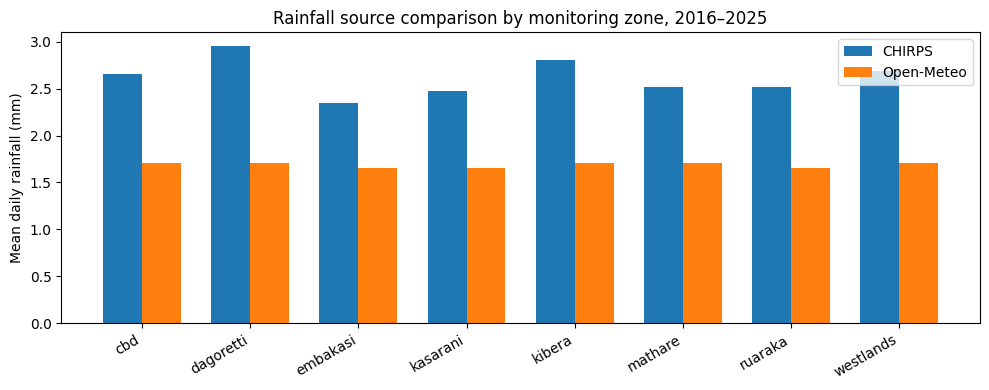

In [ ]:
#Checking source disagreement and zone-level rainfall characteristics
rain_summary = combined.groupby("zone_id", as_index=False).agg(
    chirps_mean_mm_day=("chirps_daily_rain_mm", "mean"),
    meteo_mean_mm_day=("meteo_daily_rain_mm", "mean"),
    chirps_max_mm_day=("chirps_daily_rain_mm", "max"),
    meteo_max_mm_day=("meteo_daily_rain_mm", "max"),
)
display(rain_summary.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(rain_summary))
ax.bar(x - 0.18, rain_summary["chirps_mean_mm_day"], width=0.36, label="CHIRPS")
ax.bar(x + 0.18, rain_summary["meteo_mean_mm_day"], width=0.36, label="Open-Meteo")
ax.set_xticks(x, rain_summary["zone_id"], rotation=30, ha="right")
ax.set_ylabel("Mean daily rainfall (mm)")
ax.set_title("Rainfall source comparison by monitoring zone, 2016–2025")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
#Adding strictly preceding-day CHIRPS history(computes previous day CHIRPS context to be used for next-day forecast)
combined["chirps_prev_1d_mm"] = combined.groupby("zone_id")["chirps_daily_rain_mm"].shift(1)
for n in (3, 7):
    combined[f"chirps_prev_{n}d_sum_mm"] = (
        combined.groupby("zone_id")["chirps_daily_rain_mm"]
        .transform(lambda s, window=n: s.shift(1).rolling(window, min_periods=window).sum())
    )

combined["month"] = combined["date"].dt.month
combined["day_of_year"] = combined["date"].dt.dayofyear
combined["season_sin"] = np.sin(2 * np.pi * combined["day_of_year"] / 365.25)
combined["season_cos"] = np.cos(2 * np.pi * combined["day_of_year"] / 365.25)

# For later experiments: date for which a next-day prediction would be evaluated.
combined["candidate_target_date_next_day"] = combined["date"] + pd.Timedelta(days=1)

print("Rows with incomplete preceding 7-day CHIRPS context:",
      int(combined["chirps_prev_7d_sum_mm"].isna().sum()))
print("Expected: first seven days for each of eight zones =", 7 * len(EXPECTED_ZONES))
assert combined["chirps_prev_7d_sum_mm"].isna().sum() == 7 * len(EXPECTED_ZONES)

print("No target label or verified flood probability has been constructed.")
display(combined[["zone_id", "date", "chirps_daily_rain_mm", "chirps_prev_1d_mm",
                  "chirps_prev_3d_sum_mm", "chirps_prev_7d_sum_mm"]].head(9))

Rows with incomplete preceding 7-day CHIRPS context: 56
Expected: first seven days for each of eight zones = 56
No target label or verified flood probability has been constructed.


,zone_id,date,chirps_daily_rain_mm,chirps_prev_1d_mm,chirps_prev_3d_sum_mm,chirps_prev_7d_sum_mm
0,cbd,2016-01-01,0.0,NaN,NaN,NaN
1,cbd,2016-01-02,0.0,0.0,NaN,NaN
2,cbd,2016-01-03,0.0,0.0,NaN,NaN
3,cbd,2016-01-04,0.0,0.0,0.0,NaN
4,cbd,2016-01-05,0.0,0.0,0.0,NaN
5,cbd,2016-01-06,0.0,0.0,0.0,NaN
6,cbd,2016-01-07,0.0,0.0,0.0,NaN
7,cbd,2016-01-08,0.0,0.0,0.0,0.0
8,cbd,2016-01-09,0.0,0.0,0.0,0.0


In [ ]:
#Creating chronological partitions & saving the intergrated data
train = combined[combined["date"].dt.year.between(2016, 2022)].copy()
validation = combined[combined["date"].dt.year.eq(2023)].copy()
test = combined[combined["date"].dt.year.between(2024, 2025)].copy()

assert len(train) + len(validation) + len(test) == len(combined)
assert set(train["date"]).isdisjoint(set(validation["date"]))
assert set(train["date"]).isdisjoint(set(test["date"]))
assert set(validation["date"]).isdisjoint(set(test["date"]))

outputs = {
    "NairobiFloodWatch_zone_daily_integrated_2016_2025.csv": combined,
    "NairobiFloodWatch_unlabelled_train_2016_2022.csv": train,
    "NairobiFloodWatch_unlabelled_validation_2023.csv": validation,
    "NairobiFloodWatch_unlabelled_test_2024_2025.csv": test,
}
for filename, data in outputs.items():
    output_path = OUTPUT_DIR / filename
    data.to_csv(output_path, index=False)
    print(f"Saved {output_path} | rows: {len(data):,}")

summary = {
    "project": "NairobiFloodWatch",
    "stage": "Part 1 — data preparation only; NO labels or trained model",
    "date_range": [str(START_DATE.date()), str(END_DATE.date())],
    "zones": sorted(EXPECTED_ZONES),
    "rows": {"integrated": len(combined), "train": len(train),
             "validation": len(validation), "test": len(test)},
    "source_files": {"corrected_chirps": source_chirps,
                     "open_meteo": source_weather, "terrain": source_terrain},
    "missing_chirps_rainfall": int(chirps["precipitation"].isna().sum()),
    "duplicate_zone_dates": int(combined.duplicated(["zone_id", "date"]).sum()),
    "exactly_identical_daily_open_meteo_rainfall_pairs": identical_pairs(meteo_wide),
    "important_limitations": [
        "Historical ERA5-Seamless weather is retrospective and may not be available live at issue time.",
        "CHIRPS daily dates and Nairobi-local weather day boundaries / release delays need verification.",
        "CHIRPS is a gridded satellite estimate; nearby monitoring rectangles are not independent stations.",
        "Static terrain/NDVI/land-cover summaries cannot represent changing annual land cover throughout 2016–2025.",
        "There are no verified observed flood/non-flood labels and no calibrated flood-occurrence probabilities.",
        "The eight monitoring rectangles are approximate, not official administrative sub-counties.",
        "No synthetic water-level inputs are included."
    ],
}
summary_path = OUTPUT_DIR / "NairobiFloodWatch_data_quality_manifest.json"
summary_path.write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("Saved", summary_path)
print("\nChronological partitions:")
display(pd.DataFrame([{"split": "Train", "rows": len(train), "years": "2016–2022"},
                      {"split": "Validation", "rows": len(validation), "years": "2023"},
                      {"split": "Test", "rows": len(test), "years": "2024–2025"}]))

Saved /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/NairobiFloodWatch_zone_daily_integrated_2016_2025.csv | rows: 29,224
Saved /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/NairobiFloodWatch_unlabelled_train_2016_2022.csv | rows: 20,456
Saved /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/NairobiFloodWatch_unlabelled_validation_2023.csv | rows: 2,920
Saved /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/NairobiFloodWatch_unlabelled_test_2024_2025.csv | rows: 5,848
Saved /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/NairobiFloodWatch_data_quality_manifest.json

Chronological partitions:


,split,rows,years
0,Train,20456,2016–2022
1,Validation,2920,2023
2,Test,5848,2024–2025


Part 2-Model Development


In [ ]:
#Connecting to the Drive & accessing the integrated CSV
import sys, json, platform, hashlib, zipfile, warnings
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import xgboost as xgb
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost>=2.0"])
    import xgboost as xgb

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_recall_fscore_support,
    recall_score, log_loss
)
from sklearn.utils.class_weight import compute_sample_weight
import sklearn
import joblib

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Project Dataset')
else:
    ROOT = Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()

candidates = [
    ROOT / 'NairobiFloodWatch_outputs' / 'NairobiFloodWatch_zone_daily_integrated_2016_2025.csv',
    ROOT / 'NairobiFloodWatch_zone_daily_integrated_2016_2025.csv',
    ROOT / 'NairobiFloodWatch_zone_daily_integrated_2016_2025(1).csv',
]
found = next((p for p in candidates if p.is_file()), None)
if found is None:
    raise FileNotFoundError('Part 1 integrated CSV not found. Checked: ' + ', '.join(str(p) for p in candidates))

INPUT_CSV = found
OUT = ROOT / 'NairobiFloodWatch_outputs' / 'Part2_XGBoost'
OUT.mkdir(parents=True, exist_ok=True)
print('Input:', INPUT_CSV)
print('Results folder:', OUT)
print('XGBoost:', xgb.__version__, '| scikit-learn:', sklearn.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Input: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/NairobiFloodWatch_zone_daily_integrated_2016_2025.csv
Results folder: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost
XGBoost: 3.4.1 | scikit-learn: 1.6.1


In [ ]:
#Validating the real integrated data & feature schema
raw = pd.read_csv(INPUT_CSV, parse_dates=['date', 'candidate_target_date_next_day'])
ZONES = {'cbd','dagoretti','embakasi','kasarani','kibera','mathare','ruaraka','westlands'}
REQUIRED = {
    'date','zone_id','candidate_target_date_next_day',
    'chirps_daily_rain_mm','chirps_prev_1d_mm','chirps_prev_3d_sum_mm','chirps_prev_7d_sum_mm',
    'meteo_daily_rain_mm','rainfall_3h_eod_mm','rainfall_6h_eod_mm',
    'rainfall_12h_eod_mm','rainfall_24h_eod_mm','temperature_mean_c',
    'humidity_mean_pct','wind_speed_mean_kmh','soil_moisture_mean_m3m3',
    'soil_moisture_eod_m3m3','slope_degrees','ndvi',
    'impervious_fraction','vegetation_fraction','season_sin','season_cos'
}
missing_cols = REQUIRED.difference(raw.columns)
assert not missing_cols, f'Missing columns: {sorted(missing_cols)}'
assert set(raw.zone_id) == ZONES, 'Unexpected monitoring zones'
assert len(raw) == 29224, f'Expected 29224 rows; got {len(raw)}'
assert not raw.duplicated(['zone_id','date']).any(), 'Duplicate zone/date keys'
assert raw['chirps_daily_rain_mm'].notna().all(), 'CHIRPS rainfall missing — check corrected file'
assert (raw['chirps_daily_rain_mm'] >= 0).all(), 'Negative rainfall in CHIRPS'
assert (raw.candidate_target_date_next_day == raw.date + pd.Timedelta(days=1)).all()
assert (raw.groupby('zone_id')['date'].nunique() == 3653).all()
raw = raw.sort_values(['zone_id','date']).reset_index(drop=True)
print(f'Validated {len(raw):,} observations across {raw.zone_id.nunique()} zones.')
print('Range:',raw.date.min().date(),'to',raw.date.max().date())
print('Missing counts (nonzero only):')
print(raw.isna().sum()[raw.isna().sum().gt(0)].to_string())

Validated 29,224 observations across 8 zones.
Range: 2016-01-01 to 2025-12-31
Missing counts (nonzero only):
chirps_prev_1d_mm         8
chirps_prev_3d_sum_mm    24
chirps_prev_7d_sum_mm    56


In [ ]:
#Defining next-day environmental proxy-risk target
CLASS_NAMES = ['Low','Moderate','High','Extreme']
LABELS = np.array([0,1,2,3])
g = raw.groupby('zone_id', sort=False)
# Tomorrow's CHIRPS precipitation and the 7-day sum *ending tomorrow*.
raw['audit_tomorrow_chirps_mm'] = g['chirps_daily_rain_mm'].shift(-1)
rolling7 = g['chirps_daily_rain_mm'].transform(lambda s: s.rolling(7, min_periods=7).sum())
raw['audit_7day_ending_tomorrow_mm'] = rolling7.groupby(raw['zone_id']).shift(-1)

p = raw['audit_tomorrow_chirps_mm']
r7 = raw['audit_7day_ending_tomorrow_mm']
raw['proxy_class_next_day'] = np.select(
    [(p >= 40) | (r7 >= 150), (p >= 20) | (r7 >= 80), (p >= 5) | (r7 >= 25)],
    [3,2,1], default=0
).astype('int8')
raw['target_date'] = raw.date + pd.Timedelta(days=1)

# First seven input dates of each zone lack complete previous-7-day predictor history;
# the final day of each zone has no known tomorrow.
feature_history_ok = raw['chirps_prev_7d_sum_mm'].notna()
label_ok = p.notna() & r7.notna()
model_df = raw.loc[feature_history_ok & label_ok].copy()

print('Rows with complete features and known next-day proxy targets:',len(model_df))
print('Rows excluded:',len(raw)-len(model_df))
print('Proxy label counts:')
print(model_df.proxy_class_next_day.map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES,fill_value=0))
print('By outcome year:')
display(pd.crosstab(model_df.target_date.dt.year, model_df.proxy_class_next_day).rename(columns=dict(enumerate(CLASS_NAMES))))

Rows with complete features and known next-day proxy targets: 29160
Rows excluded: 64
Proxy label counts:
proxy_class_next_day
Low         21450
Moderate     5160
High         1870
Extreme       680
Name: count, dtype: int64
By outcome year:


proxy_class_next_day,Low,Moderate,High,Extreme
target_date,,,,
2016,2211,404,214,35
2017,2323,493,88,16
2018,1940,587,288,105
2019,2142,475,211,92
2020,1932,764,154,78
2021,2265,478,109,68
2022,2316,510,80,14
2023,2285,440,148,47
2024,1926,452,375,175


In [ ]:
#Freezing predictors the model may see
RAINFALL_FEATURES = [
    'chirps_daily_rain_mm','chirps_prev_1d_mm','chirps_prev_3d_sum_mm','chirps_prev_7d_sum_mm',
    'meteo_daily_rain_mm','rainfall_3h_eod_mm','rainfall_6h_eod_mm',
    'rainfall_12h_eod_mm','rainfall_24h_eod_mm'
]
WEATHER_FEATURES = [
    'temperature_mean_c','humidity_mean_pct','wind_speed_mean_kmh',
    'soil_moisture_mean_m3m3','soil_moisture_eod_m3m3'
]
TERRAIN_FEATURES = ['slope_degrees','ndvi','impervious_fraction','vegetation_fraction']
SEASON_FEATURES = ['season_sin','season_cos']
FEATURES = RAINFALL_FEATURES + WEATHER_FEATURES + TERRAIN_FEATURES + SEASON_FEATURES
FEATURES_NO_TERRAIN = [f for f in FEATURES if f not in TERRAIN_FEATURES]
assert len(FEATURES) == len(set(FEATURES)) == 20
assert not model_df[FEATURES].isna().any().any(), 'Missing predictor values after context exclusions'
assert np.isfinite(model_df[FEATURES].to_numpy(dtype='float64')).all(), 'Nonfinite predictors'
assert not set(FEATURES) & {'audit_tomorrow_chirps_mm','audit_7day_ending_tomorrow_mm',
                             'proxy_class_next_day','target_date','candidate_target_date_next_day'}
print('Number of numeric features:',len(FEATURES))
print(*[f'{i:02d}. {x}' for i,x in enumerate(FEATURES,1)], sep=chr(10))

Number of numeric features: 20
01. chirps_daily_rain_mm
02. chirps_prev_1d_mm
03. chirps_prev_3d_sum_mm
04. chirps_prev_7d_sum_mm
05. meteo_daily_rain_mm
06. rainfall_3h_eod_mm
07. rainfall_6h_eod_mm
08. rainfall_12h_eod_mm
09. rainfall_24h_eod_mm
10. temperature_mean_c
11. humidity_mean_pct
12. wind_speed_mean_kmh
13. soil_moisture_mean_m3m3
14. soil_moisture_eod_m3m3
15. slope_degrees
16. ndvi
17. impervious_fraction
18. vegetation_fraction
19. season_sin
20. season_cos


In [ ]:
#Chronological partitions by target date
train = model_df[model_df.target_date.dt.year.between(2016,2022)].copy()
val = model_df[model_df.target_date.dt.year.eq(2023)].copy()
test = model_df[model_df.target_date.dt.year.between(2024,2025)].copy()
assert len(train)+len(val)+len(test) == len(model_df)
for a,b in [(train,val),(train,test),(val,test)]:
    assert set(a.target_date).isdisjoint(set(b.target_date)), 'Date leakage across partitions'

FROZEN_COLS = ['date','target_date','zone_id',*FEATURES,'proxy_class_next_day']
for name,part in [('train_2016_2022',train),('validation_2023',val),('test_2024_2025',test)]:
    dst=OUT / f'NairobiFloodWatch_frozen_{name}.csv'
    part[FROZEN_COLS].to_csv(dst,index=False)
    print(name,part.shape[0],'rows →',dst.name)
print('No future-rainfall label construction fields are included in the frozen splits.')
print(pd.concat([train.assign(split='train'),val.assign(split='validation'),test.assign(split='test')])
      .groupby('split').agg(rows=('date','size'),start_target=('target_date','min'),end_target=('target_date','max')))
print('Labels by partition:')
display(pd.crosstab(
    pd.Series(np.select([model_df.index.isin(train.index),model_df.index.isin(val.index)],
                        ['Train','Validation'],default='Test'),index=model_df.index,name='split'),
    model_df.proxy_class_next_day
).rename(columns=dict(enumerate(CLASS_NAMES))))

train_2016_2022 20392 rows → NairobiFloodWatch_frozen_train_2016_2022.csv
validation_2023 2920 rows → NairobiFloodWatch_frozen_validation_2023.csv
test_2024_2025 5848 rows → NairobiFloodWatch_frozen_test_2024_2025.csv
No future-rainfall label construction fields are included in the frozen splits.
             rows start_target end_target
split                                    
test         5848   2024-01-01 2025-12-31
train       20392   2016-01-09 2022-12-31
validation   2920   2023-01-01 2023-12-31
Labels by partition:


proxy_class_next_day,Low,Moderate,High,Extreme
split,,,,
Test,4036,1009,578,225
Train,15129,3711,1144,408
Validation,2285,440,148,47


In [ ]:
#Evaluation metrics & training configurations
from sklearn.metrics import precision_score

def metric_summary(y_true, y_pred, y_scores=None):
    d = {
        'accuracy': float(accuracy_score(y_true,y_pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true,y_pred)),
        'macro_f1': float(f1_score(y_true,y_pred,labels=LABELS,average='macro',zero_division=0)),
        'weighted_f1': float(f1_score(y_true,y_pred,labels=LABELS,average='weighted',zero_division=0)),
        'macro_precision': float(precision_score(y_true,y_pred,labels=LABELS,average='macro',zero_division=0)),
        'macro_recall': float(recall_score(y_true,y_pred,labels=LABELS,average='macro',zero_division=0)),
    }
    by_class = recall_score(y_true,y_pred,labels=LABELS,average=None,zero_division=0)
    d['high_recall'] = float(by_class[2])
    d['extreme_recall'] = float(by_class[3])
    d['severe_macro_recall'] = float((by_class[2]+by_class[3])/2)
    if y_scores is not None:
        d['proxy_multiclass_log_loss'] = float(log_loss(y_true,y_scores,labels=LABELS))
        onehot = np.eye(4)[np.asarray(y_true,dtype=int)]
        d['proxy_multiclass_brier'] = float(np.mean(np.sum((y_scores-onehot)**2,axis=1)))
    return d

CONFIGS = [
    {'name':'xgb_depth3_weighted','max_depth':3,'learning_rate':0.06,'min_child_weight':4,
     'reg_lambda':5,'subsample':0.85,'colsample_bytree':0.9,'weighted':True},
    {'name':'xgb_depth5_weighted','max_depth':5,'learning_rate':0.04,'min_child_weight':5,
     'reg_lambda':7,'subsample':0.85,'colsample_bytree':0.9,'weighted':True},
    {'name':'xgb_depth4_unweighted','max_depth':4,'learning_rate':0.05,'min_child_weight':4,
     'reg_lambda':5,'subsample':0.85,'colsample_bytree':0.9,'weighted':False},
]
BASE_KW = dict(objective='multi:softprob',num_class=4,n_estimators=500,
               tree_method='hist',eval_metric='mlogloss',random_state=42,
               n_jobs=2,verbosity=0)

def build_xgb(cfg, n_estimators=500, early_stopping_rounds=None):
    return xgb.XGBClassifier(**{
        **BASE_KW,**{k:v for k,v in cfg.items() if k in
           ['max_depth','learning_rate','min_child_weight','reg_lambda','subsample','colsample_bytree']},
        'n_estimators':n_estimators,'early_stopping_rounds':early_stopping_rounds,
    })

Xtr, ytr = train[FEATURES],train.proxy_class_next_day.astype(int)
Xva, yva = val[FEATURES],val.proxy_class_next_day.astype(int)
print('Train matrix',Xtr.shape,'| Validation matrix',Xva.shape)

Train matrix (20392, 20) | Validation matrix (2920, 20)


In [ ]:
#Training & Comparing XGBoost configurations
records = []
models = {}
for cfg in CONFIGS:
    weights = compute_sample_weight('balanced',ytr) if cfg['weighted'] else None
    model = build_xgb(cfg,early_stopping_rounds=40)
    model.fit(Xtr,ytr,sample_weight=weights,eval_set=[(Xva,yva)],verbose=False)
    probs = model.predict_proba(Xva)
    pred = probs.argmax(axis=1)
    result = {'config':cfg['name'],'best_trees':int(model.best_iteration)+1,
              'weighted_training':cfg['weighted'],**metric_summary(yva,pred,probs)}
    records.append(result)
    models[cfg['name']] = model
    print(f"{cfg['name']}: val macro F1={result['macro_f1']:.3f}, severe recall={result['severe_macro_recall']:.3f}, trees={result['best_trees']}")

cv_results = pd.DataFrame(records).sort_values(
    ['macro_f1','severe_macro_recall'],ascending=[False,False]
).reset_index(drop=True)
cv_results.to_csv(OUT/'xgboost_validation_model_selection.csv',index=False)
display(cv_results)
WINNER_NAME = cv_results.iloc[0]['config']
WINNER_CFG = next(c for c in CONFIGS if c['name']==WINNER_NAME)
WINNER_TREES = int(cv_results.iloc[0]['best_trees'])
print('Chosen using validation only:',WINNER_NAME,'| trees:',WINNER_TREES)

xgb_depth3_weighted: val macro F1=0.548, severe recall=0.435, trees=499
xgb_depth5_weighted: val macro F1=0.561, severe recall=0.411, trees=500
xgb_depth4_unweighted: val macro F1=0.536, severe recall=0.325, trees=120


,config,best_trees,weighted_training,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,high_recall,extreme_recall,severe_macro_recall,proxy_multiclass_log_loss,proxy_multiclass_brier
0,xgb_depth5_weighted,500,True,0.844178,0.574222,0.561216,0.842216,0.578387,0.574222,0.716216,0.106383,0.411300,0.475993,0.253879
1,xgb_depth3_weighted,499,True,0.827740,0.579111,0.547581,0.830462,0.528800,0.579111,0.763514,0.106383,0.434948,0.510412,0.271341
2,xgb_depth4_unweighted,120,False,0.867466,0.513677,0.536357,0.847656,0.609177,0.513677,0.628378,0.021277,0.324827,0.390765,0.204775


Chosen using validation only: xgb_depth5_weighted | trees: 500


In [ ]:
#Testing whether the geographical features are useful
no_terrain_model = build_xgb(WINNER_CFG,early_stopping_rounds=40)
no_terrain_weights = compute_sample_weight('balanced',ytr) if WINNER_CFG['weighted'] else None
no_terrain_model.fit(train[FEATURES_NO_TERRAIN],ytr,sample_weight=no_terrain_weights,
                     eval_set=[(val[FEATURES_NO_TERRAIN],yva)],verbose=False)
no_terrain_probs = no_terrain_model.predict_proba(val[FEATURES_NO_TERRAIN])
full_model = models[WINNER_NAME]
full_probs = full_model.predict_proba(Xva)
ablation = pd.DataFrame([
    {'variant':'XGBoost with terrain / vegetation',
     **metric_summary(yva,full_probs.argmax(axis=1),full_probs)},
    {'variant':'XGBoost without terrain / vegetation',
     **metric_summary(yva,no_terrain_probs.argmax(axis=1),no_terrain_probs)}
])
ablation.to_csv(OUT/'terrain_ablation_validation.csv',index=False)
display(ablation)
print('Model training with terrain is retained for this planned experiment; ablation alone does not validate geographic flood outcomes.')

,variant,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,high_recall,extreme_recall,severe_macro_recall,proxy_multiclass_log_loss,proxy_multiclass_brier
0,XGBoost with terrain / vegetation,0.844178,0.574222,0.561216,0.842216,0.578387,0.574222,0.716216,0.106383,0.411300,0.475993,0.253879
1,XGBoost without terrain / vegetation,0.847945,0.589515,0.582799,0.846356,0.613907,0.589515,0.716216,0.148936,0.432576,0.469212,0.248038


Model training with terrain is retained for this planned experiment; ablation alone does not validate geographic flood outcomes.


In [ ]:
#Refitting final XGBoost using 2016-2023 & evaluating 2024-2025 once
train_plus_val = pd.concat([train,val],ignore_index=True).sort_values(['target_date','zone_id'])
Xfit = train_plus_val[FEATURES]
yfit = train_plus_val.proxy_class_next_day.astype(int)
fit_weights = compute_sample_weight('balanced',yfit) if WINNER_CFG['weighted'] else None
FINAL_MODEL = build_xgb(WINNER_CFG,n_estimators=WINNER_TREES,early_stopping_rounds=None)
FINAL_MODEL.fit(Xfit,yfit,sample_weight=fit_weights,verbose=False)

Xtest = test[FEATURES]
ytest = test.proxy_class_next_day.astype(int)
test_scores = FINAL_MODEL.predict_proba(Xtest)
test_pred = test_scores.argmax(axis=1)
TEST_METRICS = metric_summary(ytest,test_pred,test_scores)
print('HELD-OUT 2024–2025 TEST — PROXY RISK LABELS ONLY')
display(pd.DataFrame([TEST_METRICS]).T.rename(columns={0:'score'}))
print(classification_report(ytest,test_pred,labels=LABELS,target_names=CLASS_NAMES,zero_division=0))

HELD-OUT 2024–2025 TEST — PROXY RISK LABELS ONLY


,score
accuracy,0.809337
balanced_accuracy,0.635070
macro_f1,0.637146
weighted_f1,0.814042
macro_precision,0.664116
macro_recall,0.635070
high_recall,0.619377
extreme_recall,0.302222
severe_macro_recall,0.460800
proxy_multiclass_log_loss,0.579971


              precision    recall  f1-score   support

         Low       0.94      0.88      0.91      4036
    Moderate       0.53      0.74      0.62      1009
        High       0.64      0.62      0.63       578
     Extreme       0.54      0.30      0.39       225

    accuracy                           0.81      5848
   macro avg       0.66      0.64      0.64      5848
weighted avg       0.83      0.81      0.81      5848



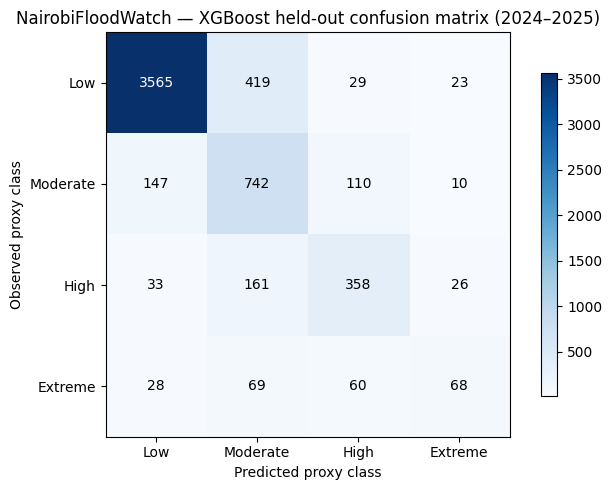

,precision,recall,f1-score,support
proxy_class,,,,
Low,0.944871,0.883300,0.913049,4036.0
Moderate,0.533429,0.735382,0.618333,1009.0
High,0.642729,0.619377,0.630837,578.0
Extreme,0.535433,0.302222,0.386364,225.0


,zone_id,rows,accuracy,macro_f1,high_recall,extreme_recall,severe_macro_recall
0,cbd,731,0.775650,0.589209,0.587500,0.258065,0.422782
1,dagoretti,731,0.787962,0.632747,0.573171,0.322581,0.447876
2,embakasi,731,0.824897,0.637703,0.619048,0.318182,0.468615
3,kasarani,731,0.845417,0.683991,0.696429,0.357143,0.526786
4,kibera,731,0.790698,0.639320,0.590909,0.344828,0.467868
5,mathare,731,0.837209,0.654197,0.681159,0.240000,0.460580
6,ruaraka,731,0.848153,0.690398,0.716667,0.357143,0.536905
7,westlands,731,0.764706,0.572765,0.550000,0.225806,0.387903


In [ ]:
#Confusion matrix, class-level, per-zone reporting
cm=confusion_matrix(ytest,test_pred,labels=LABELS)
fig,ax=plt.subplots(figsize=(7,5))
im=ax.imshow(cm,cmap='Blues')
ax.set_xticks(range(4),CLASS_NAMES);ax.set_yticks(range(4),CLASS_NAMES)
ax.set_xlabel('Predicted proxy class');ax.set_ylabel('Observed proxy class')
ax.set_title('NairobiFloodWatch — XGBoost held-out confusion matrix (2024–2025)')
for i in range(4):
    for j in range(4):
        ax.text(j,i,str(cm[i,j]),ha='center',va='center',
                color='white' if cm[i,j]>cm.max()/2 else 'black')
fig.colorbar(im,ax=ax,shrink=.8);fig.tight_layout()
fig.savefig(OUT/'xgboost_test_confusion_matrix.png',dpi=160)
plt.show()

class_report=pd.DataFrame(classification_report(
    ytest,test_pred,labels=LABELS,target_names=CLASS_NAMES,
    zero_division=0,output_dict=True)).T.loc[CLASS_NAMES]
class_report.index.name='proxy_class'
class_report.to_csv(OUT/'xgboost_test_per_class.csv')
display(class_report)

per_zone=[]
for zone, part in test.groupby('zone_id',sort=True):
    ix=part.index
    y=part.proxy_class_next_day.astype(int).to_numpy()
    prob=FINAL_MODEL.predict_proba(part[FEATURES])
    pred=prob.argmax(axis=1)
    per_zone.append({'zone_id':zone,'rows':len(part),**metric_summary(y,pred,prob)})
per_zone=pd.DataFrame(per_zone)
per_zone.to_csv(OUT/'xgboost_test_per_zone.csv',index=False)
display(per_zone[['zone_id','rows','accuracy','macro_f1','high_recall','extreme_recall','severe_macro_recall']])

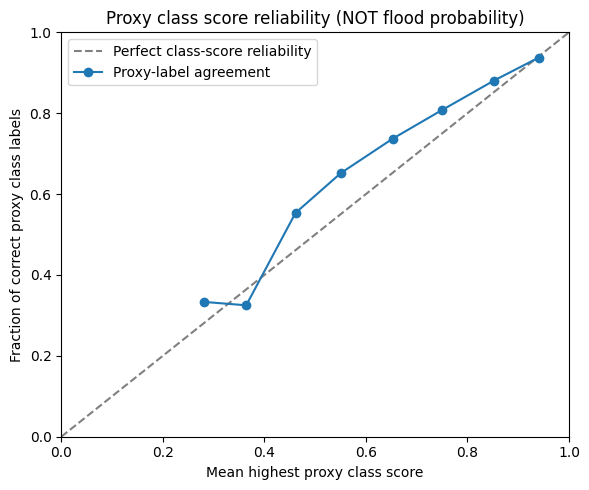

In [ ]:
#Probability-like score diagnostics
confidence = test_scores.max(axis=1)
correct = (test_pred==ytest.to_numpy()).astype(int)
bins = np.linspace(0,1,11)
rows=[]
for i in range(10):
    mask=(confidence>=bins[i]) & (confidence<bins[i+1] if i<9 else confidence<=bins[i+1])
    if mask.sum():
        rows.append({'lower_bound':bins[i],'upper_bound':bins[i+1],
                     'samples':int(mask.sum()),'mean_score':float(confidence[mask].mean()),
                     'fraction_correct_proxy_class':float(correct[mask].mean())})
reliability=pd.DataFrame(rows)
reliability.to_csv(OUT/'proxy_score_confidence_bins.csv',index=False)
fig,ax=plt.subplots(figsize=(6,5))
ax.plot([0,1],[0,1],'--',color='gray',label='Perfect class-score reliability')
ax.plot(reliability.mean_score,reliability.fraction_correct_proxy_class,'o-',label='Proxy-label agreement')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean highest proxy class score',
       ylabel='Fraction of correct proxy class labels',
       title='Proxy class score reliability (NOT flood probability)')
ax.legend();fig.tight_layout()
fig.savefig(OUT/'proxy_class_score_reliability.png',dpi=160)
plt.show()

In [ ]:
#Next-day rainfall-event diagnostic
true_heavy=(test['audit_tomorrow_chirps_mm'].to_numpy()>=20)
flag_severe=np.isin(test_pred,[2,3])
heavy_tp=int((true_heavy & flag_severe).sum())
heavy_fn=int((true_heavy & ~flag_severe).sum())
heavy_fp=int((~true_heavy & flag_severe).sum())
print('Heavy next-day CHIRPS rainfall >=20 mm:',int(true_heavy.sum()),'days×zones')
print('Severe-proxy warning recall for heavy rainfall:',
      round(heavy_tp/max(1,heavy_tp+heavy_fn),3))
print('Severe-proxy warning precision for heavy rainfall:',
      round(heavy_tp/max(1,heavy_tp+heavy_fp),3))
print('This is not measured flooding; no historical flood labels have been supplied.')

Heavy next-day CHIRPS rainfall >=20 mm: 349 days×zones
Severe-proxy warning recall for heavy rainfall: 0.398
Severe-proxy warning precision for heavy rainfall: 0.203
This is not measured flooding; no historical flood labels have been supplied.


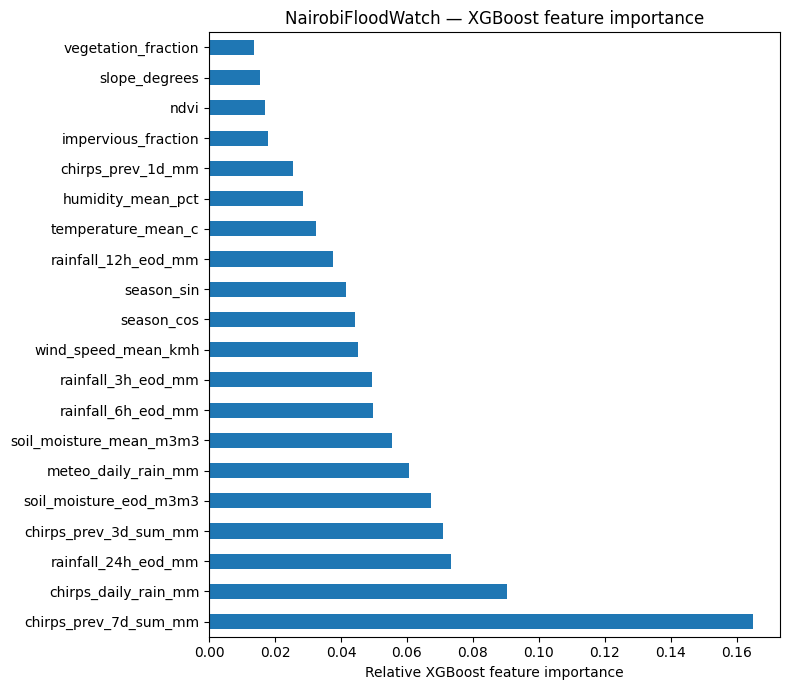

Top features:
chirps_prev_7d_sum_mm      0.164951
chirps_daily_rain_mm       0.090247
rainfall_24h_eod_mm        0.073512
chirps_prev_3d_sum_mm      0.070802
soil_moisture_eod_m3m3     0.067157
meteo_daily_rain_mm        0.060495
soil_moisture_mean_m3m3    0.055342
rainfall_6h_eod_mm         0.049782
rainfall_3h_eod_mm         0.049364
wind_speed_mean_kmh        0.045037
dtype: float32


In [ ]:
#Model feature importance
fi = pd.Series(FINAL_MODEL.feature_importances_,index=FEATURES).sort_values(ascending=False)
fi.rename('xgboost_gain_importance').rename_axis('feature').to_csv(OUT/'xgboost_feature_importances.csv')
fig,ax=plt.subplots(figsize=(8,7))
fi.tail(20).plot.barh(ax=ax)
ax.set_title('NairobiFloodWatch — XGBoost feature importance')
ax.set_xlabel('Relative XGBoost feature importance')
fig.tight_layout();fig.savefig(OUT/'xgboost_feature_importances.png',dpi=160)
plt.show()
print('Top features:');print(fi.head(10))

In [ ]:
#Saving model & experiment evidence
MODEL_PATH = OUT/'nairobi_xgboost_nextday_proxy_v1.json'
JOBLIB_PATH = OUT/'nairobi_xgboost_nextday_proxy_v1.joblib'
FINAL_MODEL.save_model(str(MODEL_PATH))
joblib.dump(FINAL_MODEL,JOBLIB_PATH)
(OUT/'feature_columns.json').write_text(json.dumps(FEATURES,indent=2),encoding='utf-8')
(OUT/'class_names.json').write_text(json.dumps(dict(enumerate(CLASS_NAMES)),indent=2),encoding='utf-8')
pd.DataFrame([TEST_METRICS]).to_csv(OUT/'xgboost_test_metrics.csv',index=False)

pred_df=test[['date','target_date','zone_id','proxy_class_next_day']].reset_index(drop=True).copy()
pred_df['predicted_proxy_class']=test_pred
for n,name in enumerate(CLASS_NAMES):
    pred_df[f'score_{name.lower()}']=test_scores[:,n]
pred_df.to_csv(OUT/'xgboost_test_predictions_proxy_only.csv',index=False)

source_hash=hashlib.sha256()
with INPUT_CSV.open('rb') as fp:
    for block in iter(lambda: fp.read(1024*1024),b''):
        source_hash.update(block)

MANIFEST={
    'project':'NairobiFloodWatch', 'experiment':'part2_xgboost_nextday_proxy_v1',
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'model_status':'research prototype only, not deployed/approved',
    'model_family':'XGBoost multiclass classifier',
    'target_kind':'rule-defined NEXT-DAY RAINFALL/ANTECEDENT-WETNESS PROXY (NOT OBSERVED FLOOD)',
    'prediction_horizon':'next calendar day after predictor input date',
    'target_rules_mm':{'extreme':'next_day_CHIRPS >= 40 OR 7d_total_ending_next_day >= 150',
                       'high':'next_day_CHIRPS >= 20 OR 7d_total_ending_next_day >= 80',
                       'moderate':'next_day_CHIRPS >= 5 OR 7d_total_ending_next_day >= 25',
                       'low':'otherwise'},
    'classes':dict(enumerate(CLASS_NAMES)),
    'feature_columns_ordered':FEATURES,'feature_count':len(FEATURES),
    'terrain_features':TERRAIN_FEATURES,
    'train_target_dates':['2016-01-01','2022-12-31'],
    'validation_target_dates':['2023-01-01','2023-12-31'],
    'test_target_dates':['2024-01-01','2025-12-31'],
    'training_refit':'train plus validation (target dates through 2023), after 2023 model selection',
    'rows':{'train':len(train),'validation':len(val),'test':len(test),'train_plus_validation':len(train_plus_val)},
    'selection_config':WINNER_CFG,'final_trees':WINNER_TREES,
    'test_metrics_proxy_labels':TEST_METRICS,
    'source_file':INPUT_CSV.name,'source_sha256':source_hash.hexdigest(),
    'packages':{'python':platform.python_version(),'pandas':pd.__version__,
                'numpy':np.__version__,'xgboost':xgb.__version__,
                'scikit_learn':sklearn.__version__},
    'limitations':[
       'Class scores are NOT calibrated probabilities of actual flood occurrence.',
       'Targets are rules built from future CHIRPS rainfall; no independently observed flood/non-flood outcomes.',
       'Some label criteria use prior 6 days of known rainfall, so accuracy partly reflects known antecedent context.',
       'CHIRPS day boundaries and publication delay versus Open-Meteo Nairobi-local days require verification.',
       'Retrospective CHIRPS and ERA5-Seamless data may not be available at prediction issue time.',
       '2023 NDVI and 2021 land cover are applied as static spatial proxies to earlier historical dates.',
       'Overlapping approximate zones and coarse weather grids are not independent monitoring gauges.',
       'No measured water levels and no synthetic water levels.',
       'Production API input generation, live-data availability, and observed-flood validation are not demonstrated.'
    ]
}
(OUT/'experiment_manifest.json').write_text(json.dumps(MANIFEST,indent=2,default=str),encoding='utf-8')
ZIP_OUT=OUT/'NairobiFloodWatch_XGBoost_Part2_Artifacts.zip'
with zipfile.ZipFile(ZIP_OUT,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for item in sorted(OUT.iterdir()):
        if item.is_file() and item!=ZIP_OUT:
            z.write(item,arcname=item.name)
print('Saved',MODEL_PATH)
print('Saved',ZIP_OUT)
print('Files:',[(p.name,round(p.stat().st_size/1024)) for p in OUT.iterdir()])

Saved /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost/nairobi_xgboost_nextday_proxy_v1.json
Saved /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost/NairobiFloodWatch_XGBoost_Part2_Artifacts.zip
Files: [('NairobiFloodWatch_frozen_train_2016_2022.csv', 4707), ('NairobiFloodWatch_frozen_validation_2023.csv', 680), ('NairobiFloodWatch_frozen_test_2024_2025.csv', 1415), ('xgboost_validation_model_selection.csv', 1), ('terrain_ablation_validation.csv', 1), ('xgboost_test_confusion_matrix.png', 68), ('xgboost_test_per_class.csv', 0), ('xgboost_test_per_zone.csv', 2), ('proxy_score_confidence_bins.csv', 1), ('proxy_class_score_reliability.png', 77), ('xgboost_feature_importances.csv', 1), ('xgboost_feature_importances.png', 105), ('nairobi_xgboost_nextday_proxy_v1.json', 5420), ('nairobi_xgboost_nextday_proxy_v1.joblib', 4003), ('feature_columns.json', 0), ('class_names.json', 0), ('xgboost_test_metrics.csv', 0), ('xgboost_test_predic

In [ ]:
#Verifying the saved model reloads with the same predictions
reloaded=xgb.XGBClassifier()
reloaded.load_model(str(MODEL_PATH))
assert np.array_equal(reloaded.predict(Xtest.iloc[:50]).astype(int),test_pred[:50])
assert np.allclose(reloaded.predict_proba(Xtest.iloc[:50]),test_scores[:50],rtol=1e-6,atol=1e-6)
print('PASSED: Reloaded model reproduces the first 50 held-out class scores.')
print('Experiment complete. XGBoost model and frozen data saved at:',OUT)
print('Remember: the saved model outputs only next-day RULE-DEFINED RISK CATEGORIES.')

PASSED: Reloaded model reproduces the first 50 held-out class scores.
Experiment complete. XGBoost model and frozen data saved at: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost
Remember: the saved model outputs only next-day RULE-DEFINED RISK CATEGORIES.


Part 2B-Diagnostics


In [ ]:
#Set up dependencies and find saved Part 2 files
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             f1_score, precision_score, recall_score)
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

candidates = [
    Path('/content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost'),
    Path('/content/NairobiFloodWatch_Part2B_Extreme_Review'),
    Path('/content'),
    Path.cwd(),
    Path('/mnt/data/_extreme_review'),
]
needed = ['NairobiFloodWatch_frozen_train_2016_2022.csv',
          'NairobiFloodWatch_frozen_validation_2023.csv', 'feature_columns.json']
DATA = next((folder for folder in candidates if all((folder/name).exists() for name in needed)), None)
if DATA is None:
    raise FileNotFoundError(
        'Frozen Part 2 datasets not found. Put the three required files in the same folder, '
        'or unzip the accompanying access package into /content/NairobiFloodWatch_Part2B_Extreme_Review.'
    )
OUT = DATA/'Part2B_Extreme_Review_Results'
OUT.mkdir(parents=True,exist_ok=True)
print('Inputs:',DATA)
print('Outputs:',OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Inputs: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost
Outputs: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost/Part2B_Extreme_Review_Results


In [ ]:
#Load the exact frozen experiment and inspect class imbalance
FEATURES = json.loads((DATA/'feature_columns.json').read_text())
train = pd.read_csv(DATA/needed[0], parse_dates=['date','target_date'])
val = pd.read_csv(DATA/needed[1],parse_dates=['date','target_date'])
assert len(FEATURES)==20
assert set(train.target_date.dt.year) <= set(range(2016,2023))
assert set(val.target_date.dt.year) == {2023}
assert set(train.target_date).isdisjoint(set(val.target_date))
assert not train[FEATURES].isna().any().any()
assert not val[FEATURES].isna().any().any()
assert not train.duplicated(['target_date','zone_id']).any()
assert not val.duplicated(['target_date','zone_id']).any()
CLASSES = ['Low','Moderate','High','Extreme']
counts = pd.DataFrame({'training':train.proxy_class_next_day.value_counts().sort_index(),
                       'validation_2023':val.proxy_class_next_day.value_counts().sort_index()})
counts.index = CLASSES
print(counts)
print('Validation Extreme observations:',int((val.proxy_class_next_day==3).sum()),
      '| Distinct Extreme target dates:',val.loc[val.proxy_class_next_day==3,'target_date'].nunique())

          training  validation_2023
Low          15129             2285
Moderate      3711              440
High          1144              148
Extreme        408               47
Validation Extreme observations: 47 | Distinct Extreme target dates: 13


In [ ]:
#Reproduce the original XGBoost validation model
CFG = dict(objective='multi:softprob',num_class=4,n_estimators=496,tree_method='hist',
           eval_metric='mlogloss',random_state=42,n_jobs=2,verbosity=0,
           max_depth=5,learning_rate=0.04,min_child_weight=5,reg_lambda=7,
           subsample=0.85,colsample_bytree=0.9)
Xtr, ytr = train[FEATURES],train.proxy_class_next_day.astype(int)
Xva, yva = val[FEATURES],val.proxy_class_next_day.astype(int)
base_model = XGBClassifier(**CFG)
base_model.fit(Xtr,ytr,sample_weight=compute_sample_weight('balanced',ytr),verbose=False)
base_scores=base_model.predict_proba(Xva)
base_pred=base_scores.argmax(axis=1)
print(classification_report(yva,base_pred,labels=[0,1,2,3],target_names=CLASSES,zero_division=0))
cm=confusion_matrix(yva,base_pred,labels=[0,1,2,3])
print('2023 validation confusion matrix — rows actual, columns predicted:')
print(pd.DataFrame(cm,index=CLASSES,columns=CLASSES))
pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(OUT/'validation_baseline_confusion.csv')

              precision    recall  f1-score   support

         Low       0.93      0.92      0.93      2285
    Moderate       0.57      0.55      0.56       440
        High       0.52      0.72      0.60       148
     Extreme       0.29      0.11      0.16        47

    accuracy                           0.84      2920
   macro avg       0.58      0.57      0.56      2920
weighted avg       0.84      0.84      0.84      2920

2023 validation confusion matrix — rows actual, columns predicted:
           Low  Moderate  High  Extreme
Low       2110       142    24        9
Moderate   149       242    48        1
High         6        34   106        2
Extreme     10         5    27        5


In [ ]:
#Quantify the Extreme recall / false-alarm tradeoff
def metrics(name, ytrue, pred):
    labels=[0,1,2,3]
    rec=recall_score(ytrue,pred,labels=labels,average=None,zero_division=0)
    pre=precision_score(ytrue,pred,labels=labels,average=None,zero_division=0)
    true_ext=(np.asarray(ytrue)==3)
    pred_ext=(np.asarray(pred)==3)
    return {'experiment':name,
            'accuracy':accuracy_score(ytrue,pred),
            'macro_f1':f1_score(ytrue,pred,labels=labels,average='macro',zero_division=0),
            'high_recall':rec[2], 'extreme_recall':rec[3], 'extreme_precision':pre[3],
            'extreme_true_positive':int((true_ext & pred_ext).sum()),
            'extreme_false_positive':int((~true_ext & pred_ext).sum()),
            'extreme_false_negative':int((true_ext & ~pred_ext).sum()),
            'predicted_extreme':int(pred_ext.sum())}

rows=[]
for multiplier in [1,1.25,1.5,2,3,4,6,10]:
    adjusted = base_scores.copy()
    adjusted[:,3] *= multiplier
    prediction=adjusted.argmax(axis=1)
    rows.append(metrics(f'Extreme score ×{multiplier:g}', yva, prediction))
threshold_results=pd.DataFrame(rows)
display(threshold_results.round(3))
threshold_results.to_csv(OUT/'validation_extreme_score_multipliers.csv',index=False)

,experiment,accuracy,macro_f1,high_recall,extreme_recall,extreme_precision,extreme_true_positive,extreme_false_positive,extreme_false_negative,predicted_extreme
0,Extreme score ×1,0.843,0.561,0.716,0.106,0.294,5,12,42,17
1,Extreme score ×1.25,0.844,0.573,0.716,0.149,0.318,7,15,40,22
2,Extreme score ×1.5,0.845,0.586,0.716,0.191,0.360,9,16,38,25
3,Extreme score ×2,0.842,0.589,0.716,0.234,0.297,11,26,36,37
4,Extreme score ×3,0.836,0.582,0.696,0.298,0.209,14,53,33,67
5,Extreme score ×4,0.828,0.579,0.669,0.404,0.170,19,93,28,112
6,Extreme score ×6,0.820,0.569,0.655,0.426,0.139,20,124,27,144
7,Extreme score ×10,0.812,0.568,0.588,0.638,0.147,30,174,17,204


In [ ]:
#Compare training-time Extreme-class weighting
weight_rows=[]
for factor in [1,2,4]:
    weights=compute_sample_weight('balanced',ytr)
    weights=np.asarray(weights)*np.where(ytr.to_numpy()==3,factor,1.)
    model=XGBClassifier(**CFG)
    model.fit(Xtr,ytr,sample_weight=weights,verbose=False)
    pred=model.predict(Xva).astype(int)
    weight_rows.append(metrics(f'Extreme training weight ×{factor}',yva,pred))
weight_results=pd.DataFrame(weight_rows)
display(weight_results.round(3))
weight_results.to_csv(OUT/'validation_extreme_training_weights.csv',index=False)

,experiment,accuracy,macro_f1,high_recall,extreme_recall,extreme_precision,extreme_true_positive,extreme_false_positive,extreme_false_negative,predicted_extreme
0,Extreme training weight ×1,0.843,0.561,0.716,0.106,0.294,5,12,42,17
1,Extreme training weight ×2,0.847,0.569,0.730,0.106,0.263,5,14,42,19
2,Extreme training weight ×4,0.840,0.597,0.716,0.277,0.283,13,33,34,46


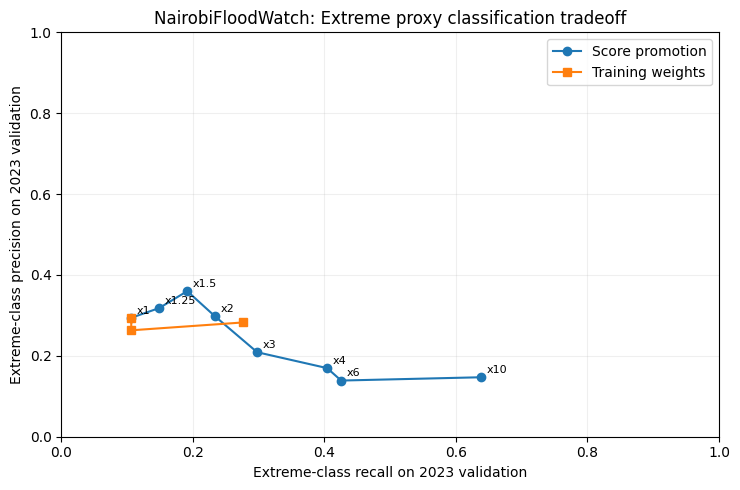

In [ ]:
#Visualise the tradeoff
fig,ax=plt.subplots(figsize=(7.5,5))
ax.plot(threshold_results['extreme_recall'],threshold_results['extreme_precision'],marker='o',label='Score promotion')
ax.plot(weight_results['extreme_recall'],weight_results['extreme_precision'],marker='s',label='Training weights')
for _, row in threshold_results.iterrows():
    ax.annotate(row['experiment'].replace('Extreme score ','').replace('×','x'),
                (row['extreme_recall'],row['extreme_precision']),xytext=(4,3),textcoords='offset points',fontsize=8)
ax.set_xlabel('Extreme-class recall on 2023 validation')
ax.set_ylabel('Extreme-class precision on 2023 validation')
ax.set_title('NairobiFloodWatch: Extreme proxy classification tradeoff')
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.grid(alpha=0.2); ax.legend()
fig.tight_layout()
fig.savefig(OUT/'validation_extreme_tradeoff.png',dpi=140)
plt.show()

In [ ]:
#Inspect previously published 2024–2025 test predictions
pred_file=DATA/'xgboost_test_predictions_proxy_only.csv'
if pred_file.exists():
    historical_pred=pd.read_csv(pred_file,parse_dates=['target_date'])
    extreme=historical_pred[historical_pred.proxy_class_next_day==3].copy()
    print('Original held-out model — Extreme errors by year:')
    by_year=extreme.groupby(extreme.target_date.dt.year).agg(
        extreme_observations=('zone_id','size'),
        correctly_extreme=('predicted_proxy_class',lambda x:int((x==3).sum()))
    )
    by_year['extreme_recall']=by_year.correctly_extreme/by_year.extreme_observations
    display(by_year)
    by_year.to_csv(OUT/'previous_test_extreme_by_year_DESCRIPTIVE_ONLY.csv')
    print('Original held-out model — Extreme confusion:')
    display(pd.crosstab(extreme.proxy_class_next_day,extreme.predicted_proxy_class))
else:
    print('Previous test predictions not found — skipping descriptive diagnostics.')

Original held-out model — Extreme errors by year:


,extreme_observations,correctly_extreme,extreme_recall
target_date,,,
2024,175,66,0.377143
2025,50,2,0.040000


Original held-out model — Extreme confusion:


predicted_proxy_class,0,1,2,3
proxy_class_next_day,,,,
3,28,69,60,68


In [ ]:
summary = {
    'purpose':'2023 validation-only Extreme proxy-class diagnostics',
    'training_dates':'2016–2022', 'evaluation_dates':'2023',
    'proxy_label_warning':'No independently confirmed flood labels or calibrated flood occurrence probability',
    'baseline':metrics('baseline',yva,base_pred),
    'interpretation':'Exploratory sensitivity comparisons. Do NOT select from 2024–2025 test results.',
    'files':[p.name for p in OUT.iterdir() if p.is_file()],
}
(OUT/'extreme_validation_review.json').write_text(json.dumps(summary,indent=2))
print('Saved the validation-only diagnostic reports to:',OUT)
print('Reminder: no new model has been approved or deployed.')

Saved the validation-only diagnostic reports to: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost/Part2B_Extreme_Review_Results
Reminder: no new model has been approved or deployed.


Part 3 -Random Forest

In [ ]:
#Loading packages & locating frozen part 2 Inputs
import io, json, os, zipfile, hashlib, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             classification_report, log_loss)
from sklearn.utils.class_weight import compute_sample_weight
import joblib
import matplotlib.pyplot as plt

SEED = 42
N_JOBS = 2  # Conservative default for Google Colab
INPUT_NAMES = [
    'NairobiFloodWatch_frozen_train_2016_2022.csv',
    'NairobiFloodWatch_frozen_validation_2023.csv',
    'NairobiFloodWatch_frozen_test_2024_2025.csv',
    'feature_columns.json', 'class_names.json',
    'xgboost_test_predictions_proxy_only.csv',
    'xgboost_test_metrics.csv',
    'xgboost_validation_model_selection.csv'
]
ROOTS = [Path.cwd(), Path('/content'),
         Path('/content/NairobiFloodWatch_Part3_RandomForest'),
         Path('/content/drive/MyDrive/Project Dataset'),
         Path('/content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost'),
         Path('/mnt/data/NairobiFloodWatch_Part3_RandomForest')]

def find_folder():
    for base in ROOTS:
        if all((base / n).is_file() for n in INPUT_NAMES):
            return base
    archives = []
    for base in ROOTS:
        archives += [base / 'NairobiFloodWatch_Part3_Inputs.zip',
                     base / 'NairobiFloodWatch_Part3_Complete.zip']
    for archive in archives:
        if archive.is_file():
            target = Path('/content/NairobiFloodWatch_Part3_unpacked') if Path('/content').exists() else Path.cwd()/'NairobiFloodWatch_Part3_unpacked'
            target.mkdir(parents=True,exist_ok=True)
            with zipfile.ZipFile(archive) as z:
                for member in z.namelist():
                    if Path(member).name in INPUT_NAMES:
                        (target / Path(member).name).write_bytes(z.read(member))
            if all((target/n).is_file() for n in INPUT_NAMES):
                return target
    raise FileNotFoundError('Upload NairobiFloodWatch_Part3_Inputs.zip into Colab /content, or place frozen CSVs and Part 2 baseline files together in MyDrive/Project Dataset.')

DATA = find_folder()
DRIVE = Path('/content/drive/MyDrive/Project Dataset')
OUT = (DRIVE / 'NairobiFloodWatch_outputs/Part3_RandomForest') if DRIVE.is_dir() else (Path.cwd() / 'NairobiFloodWatch_Part3_results')
OUT.mkdir(parents=True,exist_ok=True)
print('Input location:',DATA)
print('Output location:',OUT)
print('Python:',platform.python_version())

Input location: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part2_XGBoost
Output location: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part3_RandomForest
Python: 3.13.18


In [ ]:
#Verifying identical experiment data & label definitions
FEATURES = json.loads((DATA/'feature_columns.json').read_text())
CLASS_NAMES = ['Low','Moderate','High','Extreme']
LABELS = [0,1,2,3]
assert len(FEATURES) == 20 and len(set(FEATURES)) == 20
train = pd.read_csv(DATA/'NairobiFloodWatch_frozen_train_2016_2022.csv',parse_dates=['date','target_date'])
val = pd.read_csv(DATA/'NairobiFloodWatch_frozen_validation_2023.csv',parse_dates=['date','target_date'])
test = pd.read_csv(DATA/'NairobiFloodWatch_frozen_test_2024_2025.csv',parse_dates=['date','target_date'])

for label,df,years in [('train',train,{*range(2016,2023)}),('validation',val,{2023}),('test',test,{2024,2025})]:
    assert set(df.target_date.dt.year.unique()) == years,(label,df.target_date.dt.year.unique())
    assert set(FEATURES).issubset(df.columns), label
    assert df[FEATURES].notna().all().all(),label
    assert df[FEATURES].apply(pd.to_numeric,errors='coerce').notna().all().all(),label
    assert df['proxy_class_next_day'].isin(LABELS).all(),label
    assert not df.duplicated(['zone_id','target_date']).any(),label
    print(f'{label}: rows={len(df):,}, zones={df.zone_id.nunique()}, outcomes={df.proxy_class_next_day.value_counts().sort_index().to_dict()}')
assert len(train)==20392 and len(val)==2920 and len(test)==5848
X_train,y_train=train[FEATURES],train.proxy_class_next_day
X_val,y_val=val[FEATURES],val.proxy_class_next_day
X_test,y_test=test[FEATURES],test.proxy_class_next_day
print('Frozen feature order verified:', FEATURES)

train: rows=20,392, zones=8, outcomes={0: 15129, 1: 3711, 2: 1144, 3: 408}
validation: rows=2,920, zones=8, outcomes={0: 2285, 1: 440, 2: 148, 3: 47}
test: rows=5,848, zones=8, outcomes={0: 4036, 1: 1009, 2: 578, 3: 225}
Frozen feature order verified: ['chirps_daily_rain_mm', 'chirps_prev_1d_mm', 'chirps_prev_3d_sum_mm', 'chirps_prev_7d_sum_mm', 'meteo_daily_rain_mm', 'rainfall_3h_eod_mm', 'rainfall_6h_eod_mm', 'rainfall_12h_eod_mm', 'rainfall_24h_eod_mm', 'temperature_mean_c', 'humidity_mean_pct', 'wind_speed_mean_kmh', 'soil_moisture_mean_m3m3', 'soil_moisture_eod_m3m3', 'slope_degrees', 'ndvi', 'impervious_fraction', 'vegetation_fraction', 'season_sin', 'season_cos']


In [ ]:
#Definning fair evaluation metrics
def score_summary(y_true, y_pred, y_probs=None):
    y_true=np.asarray(y_true,dtype=int)
    y_pred=np.asarray(y_pred,dtype=int)
    out=dict(
        accuracy=accuracy_score(y_true,y_pred),
        balanced_accuracy=balanced_accuracy_score(y_true,y_pred),
        macro_f1=f1_score(y_true,y_pred,labels=LABELS,average='macro',zero_division=0),
        weighted_f1=f1_score(y_true,y_pred,labels=LABELS,average='weighted',zero_division=0),
        high_precision=precision_score(y_true==2,y_pred==2,zero_division=0),
        high_recall=recall_score(y_true==2,y_pred==2,zero_division=0),
        extreme_precision=precision_score(y_true==3,y_pred==3,zero_division=0),
        extreme_recall=recall_score(y_true==3,y_pred==3,zero_division=0),
        severe_recall=recall_score(y_true>=2,y_pred>=2,zero_division=0),
        extreme_false_flags=int(((y_pred==3)&(y_true!=3)).sum()),
        extreme_false_flags_per_100_zone_days=100*((y_pred==3)&(y_true!=3)).mean(),
    )
    if y_probs is not None:
        y_probs=np.asarray(y_probs,float)
        y_probs=np.clip(y_probs,1e-12,1.0)
        y_probs=y_probs/y_probs.sum(axis=1,keepdims=True)
        out['proxy_multiclass_log_loss']=log_loss(y_true,y_probs,labels=LABELS)
        out['proxy_multiclass_brier']=np.mean(np.sum((y_probs-np.eye(4)[y_true])**2,axis=1))
    return out

def align_probs(model,features):
    raw=model.predict_proba(features)
    aligned=np.zeros((len(raw),4),dtype=float)
    for i,c in enumerate(model.classes_): aligned[:,int(c)]=raw[:,i]
    return aligned

In [ ]:
#Train Random Forest
RF_CONFIGS = [
 dict(name='rf_200_leaf1',n_estimators=200,max_depth=None,min_samples_leaf=1,max_features='sqrt',class_weight=None),
 dict(name='rf_200_leaf3_balanced',n_estimators=200,max_depth=16,min_samples_leaf=3,max_features='sqrt',class_weight='balanced_subsample'),
 dict(name='rf_240_leaf2_balanced',n_estimators=240,max_depth=18,min_samples_leaf=2,max_features='sqrt',class_weight='balanced_subsample'),
 dict(name='rf_240_leaf5_balanced',n_estimators=240,max_depth=14,min_samples_leaf=5,max_features='sqrt',class_weight='balanced_subsample'),
]
val_results=[]
for cfg in RF_CONFIGS:
    params={k:v for k,v in cfg.items() if k!='name'}
    clf=RandomForestClassifier(random_state=SEED,n_jobs=N_JOBS,**params)
    clf.fit(X_train,y_train)
    p=align_probs(clf,X_val)
    m=score_summary(y_val,np.argmax(p,axis=1),p)
    val_results.append({'configuration':cfg['name'],**params,**m})
    print(f"{cfg['name']}: 2023 macro F1={m['macro_f1']:.4f} extreme recall={m['extreme_recall']:.4f} false Extreme per 100={m['extreme_false_flags_per_100_zone_days']:.3f}")
validation_results=pd.DataFrame(val_results).sort_values(['macro_f1','extreme_recall'],ascending=False)
validation_results.to_csv(OUT/'random_forest_validation_selection_2023.csv',index=False)
print('\nRanked 2023 candidates:')
display(validation_results[['configuration','macro_f1','balanced_accuracy','high_recall','extreme_recall','extreme_precision','extreme_false_flags_per_100_zone_days']])
WINNER=validation_results.iloc[0]['configuration']
WINNER_CFG=next(c for c in RF_CONFIGS if c['name']==WINNER)
print('Selected using 2023 only:',WINNER)

rf_200_leaf1: 2023 macro F1=0.5314 extreme recall=0.0000 false Extreme per 100=0.068
rf_200_leaf3_balanced: 2023 macro F1=0.5337 extreme recall=0.0000 false Extreme per 100=0.171
rf_240_leaf2_balanced: 2023 macro F1=0.5342 extreme recall=0.0000 false Extreme per 100=0.171
rf_240_leaf5_balanced: 2023 macro F1=0.5553 extreme recall=0.0426 false Extreme per 100=0.171

Ranked 2023 candidates:


,configuration,macro_f1,balanced_accuracy,high_recall,extreme_recall,extreme_precision,extreme_false_flags_per_100_zone_days
3,rf_240_leaf5_balanced,0.555334,0.559512,0.709459,0.042553,0.285714,0.171233
2,rf_240_leaf2_balanced,0.534219,0.524442,0.635135,0.000000,0.000000,0.171233
1,rf_200_leaf3_balanced,0.533699,0.532978,0.675676,0.000000,0.000000,0.171233
0,rf_200_leaf1,0.531409,0.509984,0.594595,0.000000,0.000000,0.068493


Selected using 2023 only: rf_240_leaf5_balanced


In [ ]:
#Refitting on 2016-2023 & Scoring the 2024-2025
fit_df=pd.concat([train,val],ignore_index=True).sort_values(['target_date','zone_id'])
RF_MODEL=RandomForestClassifier(random_state=SEED,n_jobs=N_JOBS,**{k:v for k,v in WINNER_CFG.items() if k!='name'})
RF_MODEL.fit(fit_df[FEATURES],fit_df.proxy_class_next_day)
rf_prob=align_probs(RF_MODEL,X_test)
rf_pred=np.argmax(rf_prob,axis=1)
rf_metrics=score_summary(y_test,rf_pred,rf_prob)
print('Random Forest 2024–2025 historical test metrics:')
print(pd.Series(rf_metrics).round(4).to_string())
print('\nClass-level RF report:')
print(classification_report(y_test,rf_pred,labels=LABELS,target_names=CLASS_NAMES,zero_division=0))

Random Forest 2024–2025 historical test metrics:
accuracy                                  0.8280
balanced_accuracy                         0.6200
macro_f1                                  0.6441
weighted_f1                               0.8259
high_precision                            0.6771
high_recall                               0.5260
extreme_precision                         0.6800
extreme_recall                            0.3022
severe_recall                             0.5567
extreme_false_flags                      32.0000
extreme_false_flags_per_100_zone_days     0.5472
proxy_multiclass_log_loss                 0.5528
proxy_multiclass_brier                    0.2760

Class-level RF report:
              precision    recall  f1-score   support

         Low       0.93      0.93      0.93      4036
    Moderate       0.57      0.73      0.64      1009
        High       0.68      0.53      0.59       578
     Extreme       0.68      0.30      0.42       225

    accuracy      

In [ ]:
#Comparing against XGBoost v1
xgb=pd.read_csv(DATA/'xgboost_test_predictions_proxy_only.csv',parse_dates=['target_date'])
xgb=xgb[['zone_id','target_date','proxy_class_next_day','predicted_proxy_class','score_low','score_moderate','score_high','score_extreme']].rename(columns={'proxy_class_next_day':'xgb_true'})
compare=test[['zone_id','target_date','proxy_class_next_day']].copy()
compare['rf_pred']=rf_pred
for i,n in enumerate(CLASS_NAMES): compare['rf_score_'+n.lower()]=rf_prob[:,i]
compare=compare.merge(xgb,on=['zone_id','target_date'],validate='one_to_one',how='left')
assert len(compare)==len(test) and compare['predicted_proxy_class'].notna().all()
assert (compare.proxy_class_next_day==compare.xgb_true).all()
yp=compare['proxy_class_next_day'].to_numpy(int)
xgb_pred=compare['predicted_proxy_class'].to_numpy(int)
xgb_prob=compare[['score_low','score_moderate','score_high','score_extreme']].to_numpy(float)
xgb_metrics=score_summary(yp,xgb_pred,xgb_prob)
rows=[{'algorithm':'XGBoost v1 (saved baseline)',**xgb_metrics},
      {'algorithm':'Random Forest (2023-selected)',**rf_metrics}]
comparison=pd.DataFrame(rows).set_index('algorithm')
comparison.to_csv(OUT/'xgboost_v1_vs_random_forest_test_2024_2025.csv')
compare.to_csv(OUT/'side_by_side_predictions_2024_2025.csv',index=False)
print('Same rows, same target, same input columns:')
display(comparison[['accuracy','macro_f1','weighted_f1','high_recall','extreme_recall','extreme_precision','severe_recall','extreme_false_flags_per_100_zone_days','proxy_multiclass_brier']])

Same rows, same target, same input columns:


,accuracy,macro_f1,weighted_f1,high_recall,extreme_recall,extreme_precision,severe_recall,extreme_false_flags_per_100_zone_days,proxy_multiclass_brier
algorithm,,,,,,,,,
XGBoost v1 (saved baseline),0.809337,0.637146,0.814042,0.619377,0.302222,0.535433,0.637609,1.008892,0.305863
Random Forest (2023-selected),0.827975,0.644097,0.825855,0.525952,0.302222,0.680000,0.556663,0.547196,0.275978


In [ ]:
#Evaluating yearly & per-zone consistency
compare['year']=compare['target_date'].dt.year
per_year=[]
per_zone=[]
for grouping,dest in [('year',per_year),('zone_id',per_zone)]:
    for gname,grp in compare.groupby(grouping):
        y=grp.proxy_class_next_day.to_numpy(int)
        for alg,col in [('XGBoost v1','predicted_proxy_class'),('Random Forest','rf_pred')]:
            dest.append({grouping:gname,'algorithm':alg,'rows':len(grp),
                         'extreme_support':int((y==3).sum()),
                         **score_summary(y,grp[col].to_numpy(int))})
per_year_df=pd.DataFrame(per_year)
per_zone_df=pd.DataFrame(per_zone)
per_year_df.to_csv(OUT/'comparison_per_year.csv',index=False)
per_zone_df.to_csv(OUT/'comparison_per_zone.csv',index=False)
print('Yearly severe-class performance:')
display(per_year_df[['year','algorithm','extreme_support','macro_f1','high_recall','extreme_recall','extreme_false_flags_per_100_zone_days']])

Yearly severe-class performance:


,year,algorithm,extreme_support,macro_f1,high_recall,extreme_recall,extreme_false_flags_per_100_zone_days
0,2024,XGBoost v1,175,0.639209,0.632000,0.377143,1.605191
1,2024,Random Forest,175,0.645010,0.517333,0.388571,0.922131
2,2025,XGBoost v1,50,0.568612,0.596059,0.040000,0.410959
3,2025,Random Forest,50,0.559598,0.541872,0.000000,0.171233


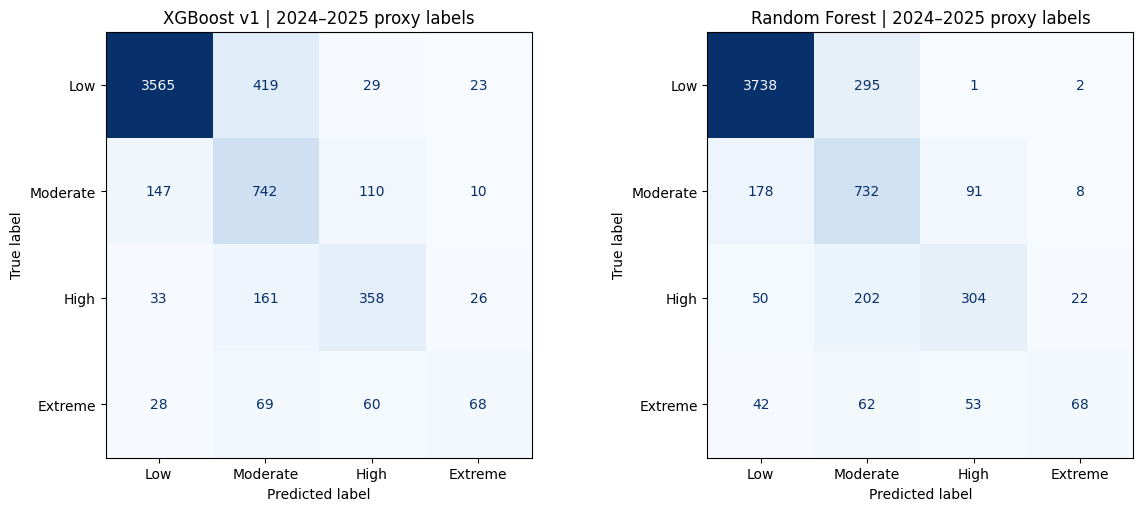

,algorithm,class,support,precision,recall,f1
0,XGBoost v1,Low,4036,0.944871,0.883300,0.913049
1,XGBoost v1,Moderate,1009,0.533429,0.735382,0.618333
2,XGBoost v1,High,578,0.642729,0.619377,0.630837
3,XGBoost v1,Extreme,225,0.535433,0.302222,0.386364
4,Random Forest,Low,4036,0.932635,0.926165,0.929388
5,Random Forest,Moderate,1009,0.567002,0.725471,0.636522
6,Random Forest,High,578,0.677060,0.525952,0.592016
7,Random Forest,Extreme,225,0.680000,0.302222,0.418462


In [ ]:
#Confusion matrices & class recall
from sklearn.metrics import ConfusionMatrixDisplay
fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,label,pred in [(axes[0],'XGBoost v1',xgb_pred),(axes[1],'Random Forest',rf_pred)]:
    ConfusionMatrixDisplay(confusion_matrix(yp,pred,labels=LABELS),display_labels=CLASS_NAMES).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(label+' | 2024–2025 proxy labels')
fig.savefig(OUT/'comparison_confusion_matrices.png',dpi=170,bbox_inches='tight')
plt.show()

class_rows=[]
for alg,pred in [('XGBoost v1',xgb_pred),('Random Forest',rf_pred)]:
    for k,name in enumerate(CLASS_NAMES):
        class_rows.append({'algorithm':alg,'class':name,'support':int((yp==k).sum()),
                           'precision':precision_score(yp==k,pred==k,zero_division=0),
                           'recall':recall_score(yp==k,pred==k,zero_division=0),
                           'f1':f1_score(yp==k,pred==k,zero_division=0)})
class_df=pd.DataFrame(class_rows)
class_df.to_csv(OUT/'comparison_per_class.csv',index=False)
display(class_df)

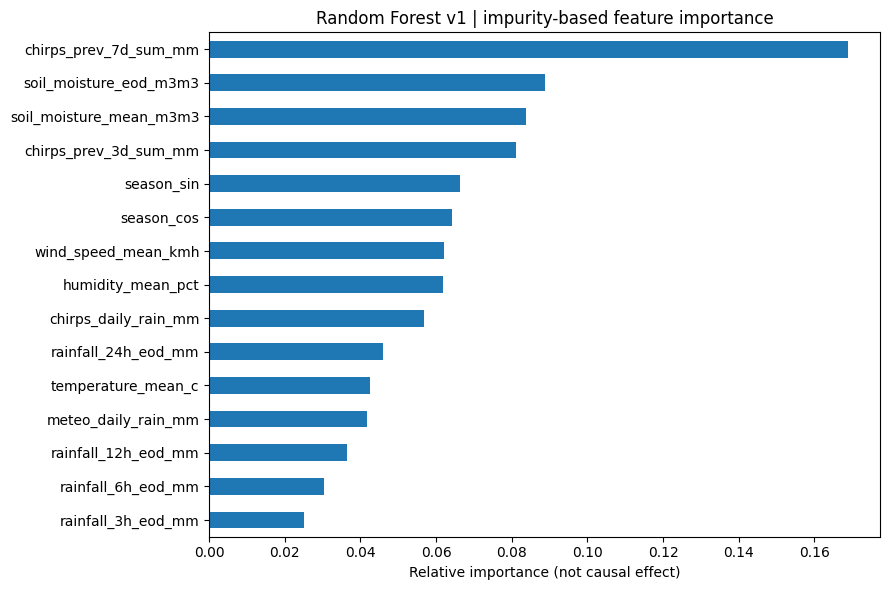

In [ ]:
#Feature Importance
fi=pd.Series(RF_MODEL.feature_importances_,index=FEATURES).sort_values(ascending=False)
fi.rename_axis('feature').reset_index(name='rf_impurity_importance').to_csv(OUT/'random_forest_feature_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(9,6))
fi.iloc[:15].sort_values().plot.barh(ax=ax)
ax.set_title('Random Forest v1 | impurity-based feature importance')
ax.set_xlabel('Relative importance (not causal effect)')
fig.tight_layout()
fig.savefig(OUT/'random_forest_feature_importance.png',dpi=160)
plt.show()

In [ ]:
#Saving model & training evidence
from datetime import datetime, timezone
MODEL_FILE=OUT/'nairobi_random_forest_nextday_proxy_v1.joblib'
joblib.dump(RF_MODEL,MODEL_FILE,compress=3)
(OUT/'feature_columns.json').write_text(json.dumps(FEATURES,indent=2))
(OUT/'class_names.json').write_text(json.dumps(CLASS_NAMES,indent=2))
(OUT/'selected_rf_configuration.json').write_text(json.dumps(WINNER_CFG,indent=2))
manifest={
 'project':'NairobiFloodWatch','experiment':'part3_random_forest_against_xgboost_v1',
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'status':'research prototype; no actual-flood labels, no calibrated flood-event probability',
 'task':'next-day CHIRPS proxy-risk multiclass classification',
 'features':FEATURES,'classes':CLASS_NAMES,
 'split_target_years':{'train':'2016-2022','validation':'2023','historical_test':'2024-2025'},
 'rows':{'train':len(train),'validation':len(val),'test':len(test)},
 'selection_basis':'2023 validation macro F1; 2024-2025 excluded from RF model selection',
 'selected_configuration':WINNER_CFG,
 'results':{'rf_test':rf_metrics,'xgb_v1_test':xgb_metrics},
 'original_baseline_source':'Part 2 archived xgboost_test_predictions_proxy_only.csv',
 'limitations':['Original XGBoost development already inspected 2024–2025, making this a historical comparison rather than a fully untouched new test.',
                'Labels are CHIRPS rule-defined proxies, not independently observed flooding.',
                'Some zones share Open-Meteo weather grid outputs and satellite data are gridded estimates.',
                'Historical reanalysis and satellite products may not be available at operational issue time.',
                'Static 2023 NDVI and 2021 land cover are applied across 2016–2025.',
                'RF predicted probabilities are not calibrated probabilities of flooding.'],
 'software':{'python':platform.python_version(),'pandas':pd.__version__,'scikit_learn':__import__('sklearn').__version__,'numpy':np.__version__}
}
(OUT/'part3_experiment_manifest.json').write_text(json.dumps(manifest,indent=2,default=str))
# Model reload and prediction agreement
reloaded=joblib.load(MODEL_FILE)
assert np.array_equal(reloaded.predict(X_test.iloc[:32]),RF_MODEL.predict(X_test.iloc[:32]))
print('RF model saved/reloaded:',MODEL_FILE)
print('Model selection preserved XGBoost v1; neither model is deployed.')

RF model saved/reloaded: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part3_RandomForest/nairobi_random_forest_nextday_proxy_v1.joblib
Model selection preserved XGBoost v1; neither model is deployed.


In [ ]:
report=['# NairobiFloodWatch — Part 3: Random Forest comparison','',
 'Prediction target: next-day CHIRPS rule-generated environmental risk, not confirmed flooding.','',
 '## Validation-selected RF configuration',f'`{WINNER_CFG}`','',
 '## Historical 2024–2025 test comparison','',comparison.round(4).to_markdown(),'','',
 '## Interpretive caveats','- The XGBoost v1 result is from the archived Part 2 predictions on the same zone-date rows.',
 '- RF was selected using 2023 validation only; no tuning from the historical 2024–2025 test.',
 '- Some locations share coarse weather-grid data; records are not independent flood events.',
 '- Do not interpret proxy-class scores as calibrated flood probabilities.',
 '- Retain XGBoost v1 and do not deploy a replacement before independent observed-event validation.']
(OUT/'Part3_Results_Summary.md').write_text('\n'.join(report))
with zipfile.ZipFile(OUT/'NairobiFloodWatch_Part3_Results.zip','w',compression=zipfile.ZIP_DEFLATED) as archive:
    for p in OUT.iterdir():
        if p.is_file() and p.name!='NairobiFloodWatch_Part3_Results.zip': archive.write(p,p.name)
print('Results folder:',OUT)
print('Artifacts ZIP:',OUT/'NairobiFloodWatch_Part3_Results.zip')

Results folder: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part3_RandomForest
Artifacts ZIP: /content/drive/MyDrive/Project Dataset/NairobiFloodWatch_outputs/Part3_RandomForest/NairobiFloodWatch_Part3_Results.zip
